<div style="background:#020B21;padding:24px 26px;border-radius:8px;">
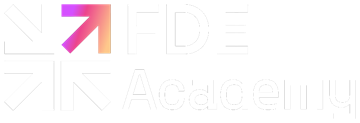<br><br>
<span style="color:#FFCA8B;font-size:13px;letter-spacing:1.5px;">TECH TRACK · LANGGRAPH · ASSIGNMENT</span><br>
<span style="color:#FFFFFF;font-size:28px;font-weight:700;">Hopscotch: Review Moderation</span><br>
<span style="color:#EC458D;font-size:14px;">State · Nodes · Edges · Branching · Parallel · Tools and ToolNode · Loops</span>
</div>

**Format:** individual

## The story

Hopscotch sells kids' clothes online and gets **about 2,000 reviews a day**. A small team reads them by hand, a week late. So abuse and phone numbers stay live for days, parents' questions go unanswered, and a bad batch is spotted only after hundreds of returns.

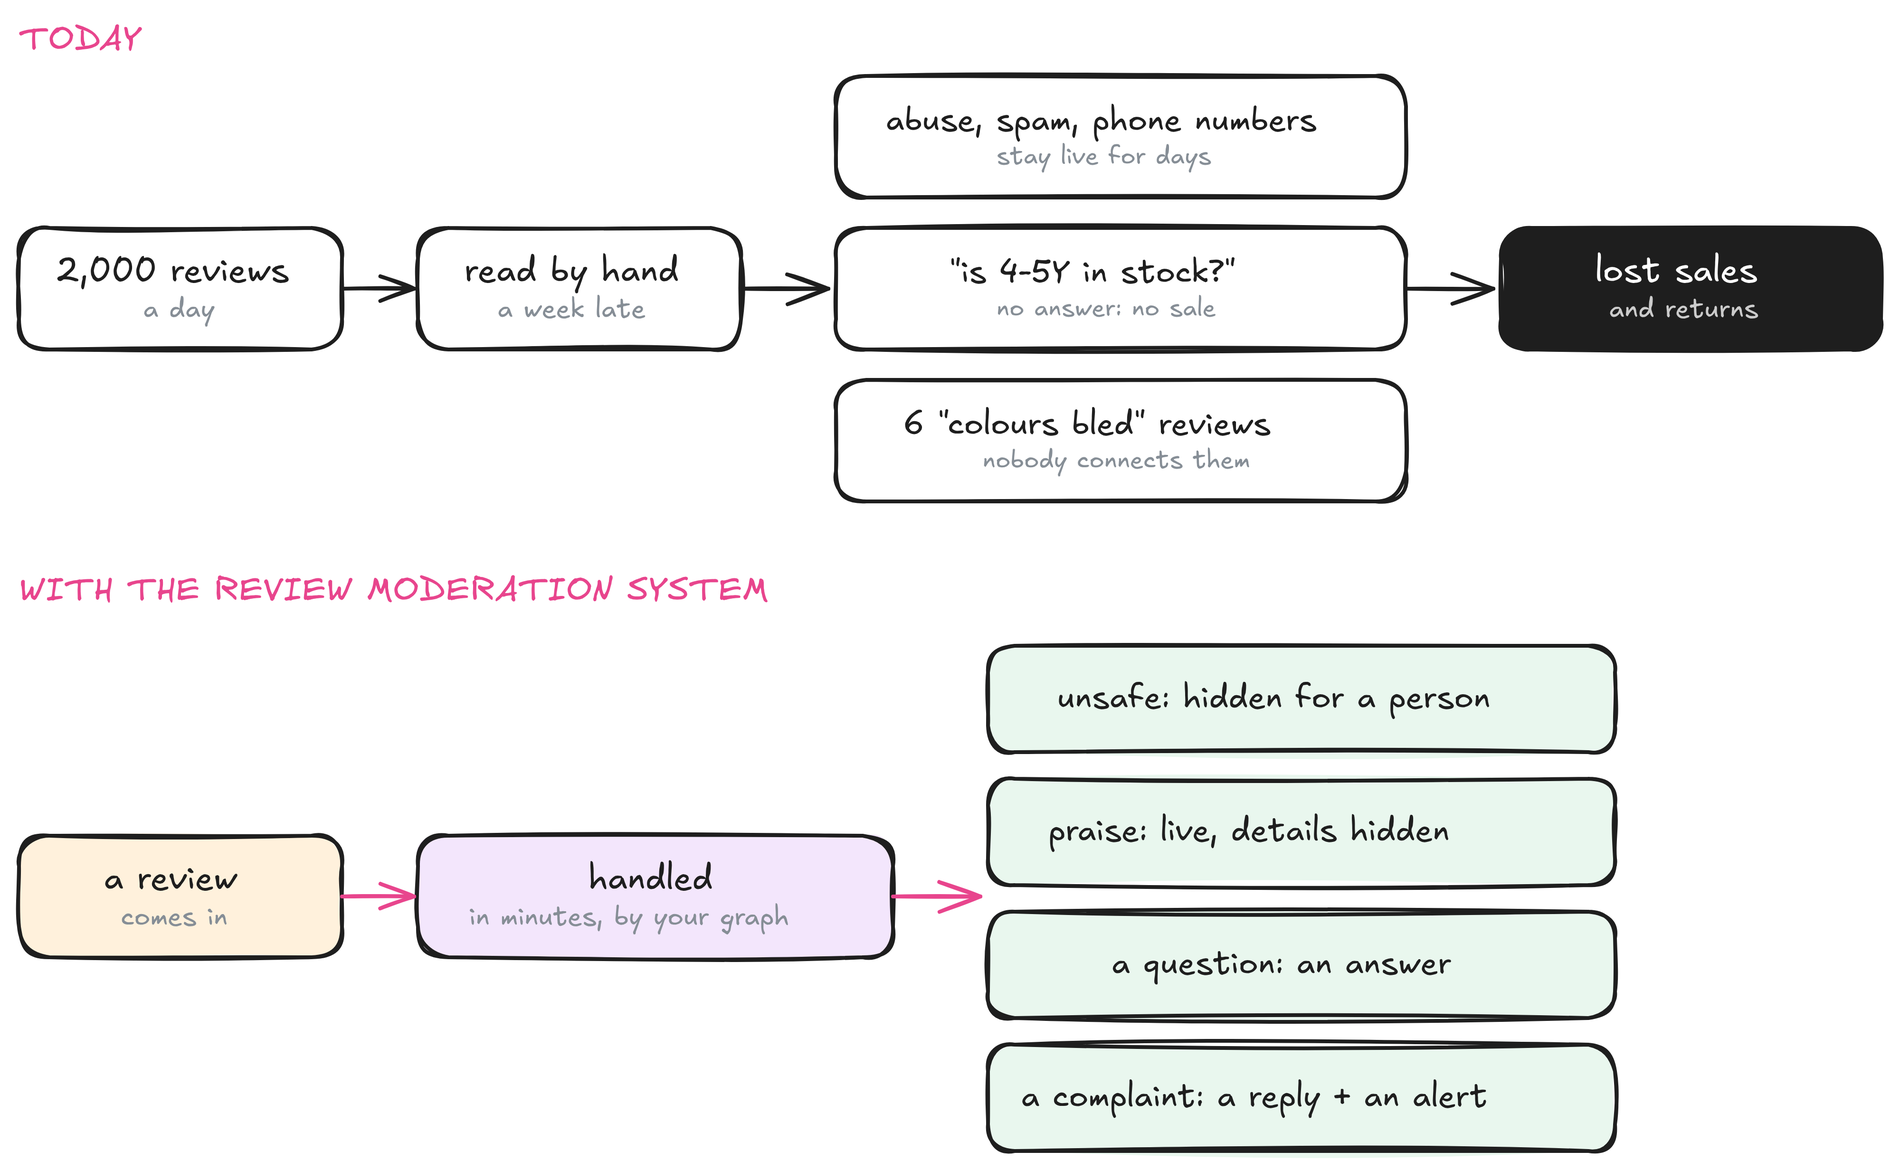

## The graph you will build

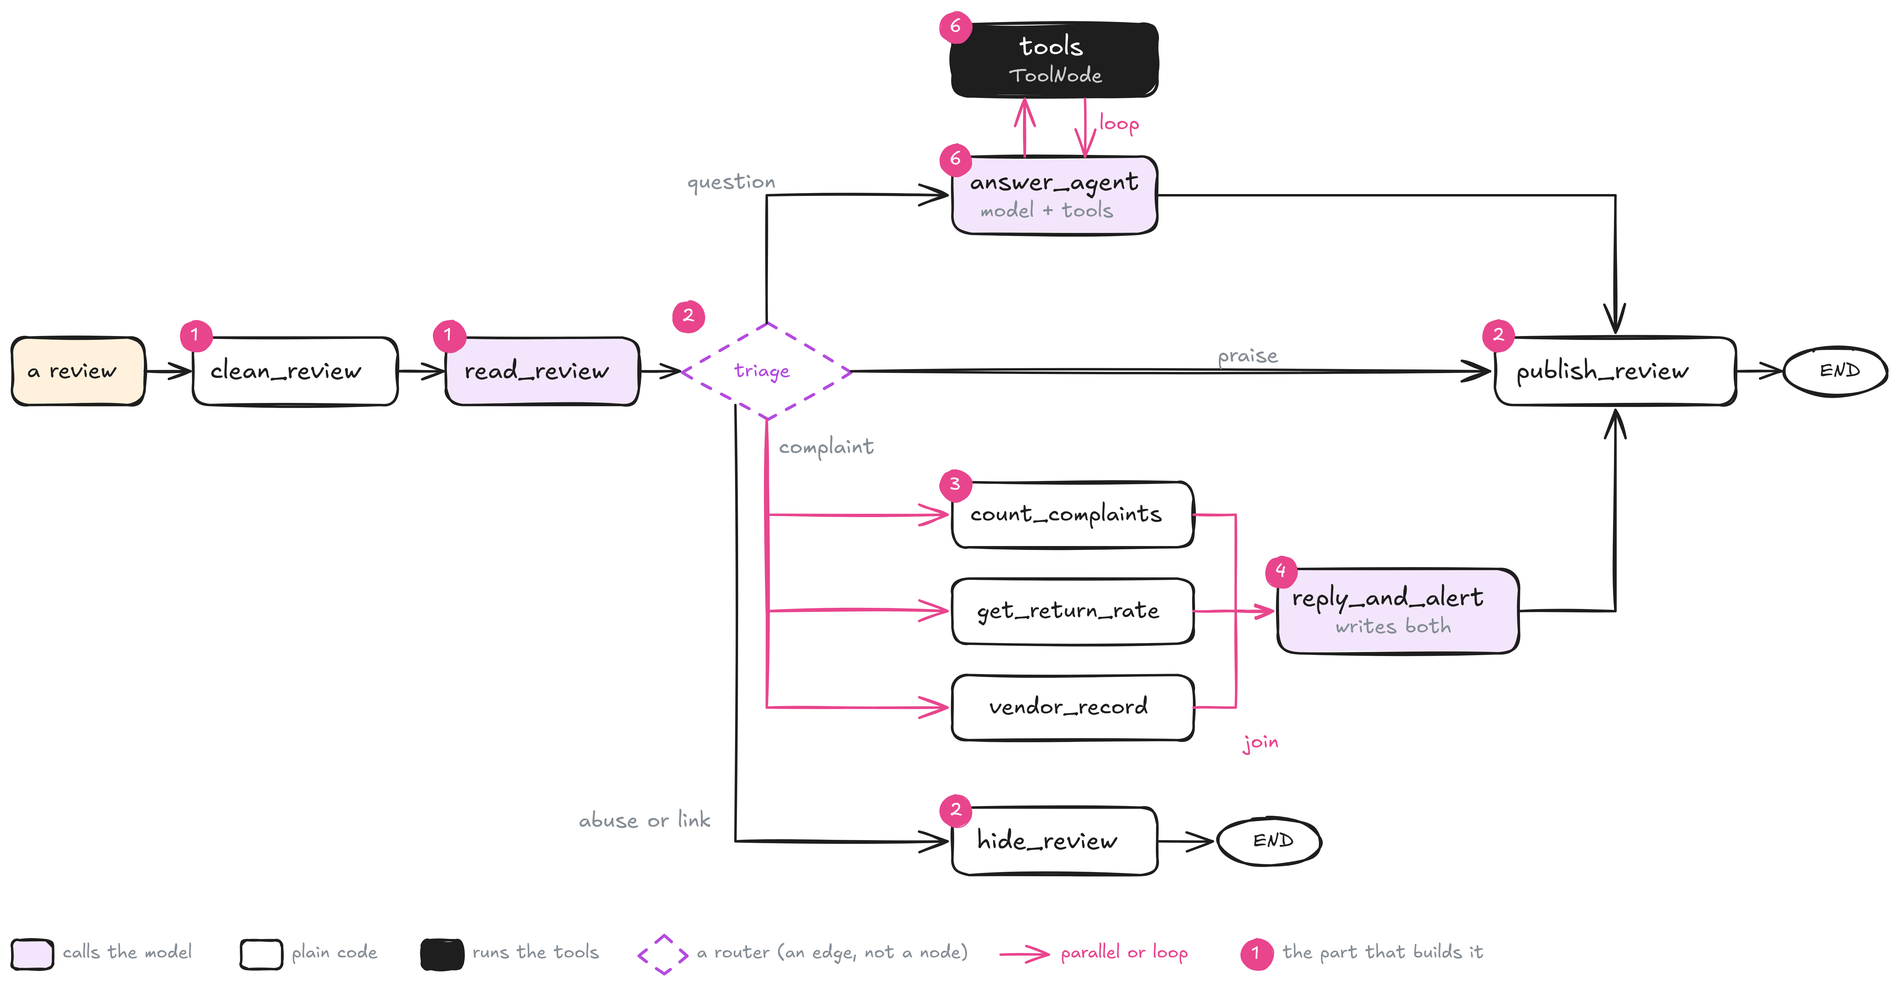

Every box is a **node** (a function that reads the shared **state** and returns an update); every arrow is an **edge**. Each review goes down the same short line, then a **router** sends it into one of four lanes:

| Lane | What happens |
|---|---|
| hide | abuse or spam: hidden for a person to check |
| publish | praise: goes live |
| question | the model looks up the facts with **tools**, in a loop, then answers |
| complaint | 3 lookups run **in parallel**, then a reply and an alert are written |

The model **reads and writes**; plain code **decides**.

**Markers:** 🛠️ your turn: fill the `...` blanks · ✅ just run it: it checks your work

## Setup

Put your key in a `.env` file next to this notebook: `OPENROUTER_API_KEY=sk-or-...`. Then run the 3 cells below. Nothing to edit.

In [195]:
# Setup 1: install the libraries (run once)
%pip install -qU "langgraph>=1.0,<2.0" "langchain-core>=1.0,<2.0" langchain-openai python-dotenv

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [196]:
# Setup 2: connect to the model
import os, re, json, time, operator
from dotenv import load_dotenv
from langchain_openai import ChatOpenAI

load_dotenv()
llm = ChatOpenAI(model="openai/gpt-4o-mini", temperature=0,
                 base_url="https://openrouter.ai/api/v1",
                 api_key=os.getenv("OPENROUTER_API_KEY"))
print("Model ready:", llm.model_name)

Model ready: openai/gpt-4o-mini


**Setup 3** has the 7 reviews you will test with, `check()` for the check cells, and `show()` to draw any graph you build. Each one takes a different path. The data each lane needs comes later, in the part that uses it.

In [197]:
# Setup 3: 7 reviews to test with, and check() for the check cells
def review(review_id, sku, rating, text):
    return {"review_id": review_id, "sku": sku, "rating": rating, "text": text}

REVIEWS = [
    review("R-1", "HS-118", 5, "Lovely soft fabric, my son wears it every day."),
    review("R-2", "HS-201", 4, "Pretty frock! Machine washable? Is 4-5Y in stock?"),
    review("R-3", "HS-201", 2, "The colours bled into each other after the very first wash."),
    review("R-4", "HS-305", 2, "One strap button came off after a week. Otherwise good."),
    review("R-5", "HS-412", 1, "Worst shoes ever, you idiots. Call me on 98200 11223."),
    review("R-6", "HS-201", 5, "Great deals on kids wear at http://cheap-kids-wear.biz"),
    review("R-7", "HS-118", 4, "My daughter is 108 cm: which size, and is it in stock?"),
]

def check(name, ok, tip=""):
    print(f"✅ {name}" if ok else f"❌ {name}  {tip}")

from IPython.display import Image, display
def show(graph):
    """Draws a compiled graph. Offline, it prints the Mermaid code instead."""
    try:
        display(Image(graph.get_graph().draw_mermaid_png()))
    except Exception:
        print(graph.get_graph().draw_mermaid())

<div style="background:#020B21;color:#FFFFFF;padding:12px 16px;border-left:6px solid #EC458D;border-radius:6px;"><span style="color:#FFCA8B;font-size:12px;letter-spacing:1px;">PART 1 OF 7</span><br><span style="font-size:20px;font-weight:700;">The state and the first two nodes</span><br><span style="color:#D451FF;font-size:13px;">TypedDict state · a plain-code node · a model node · edges in a row</span></div>

> **Key idea:** the **state** is one dict that travels through the graph. Each node gets the whole state and returns **only the keys it changes**.

### 1a. The state (given)

Grouped by the lane that fills it. A review only fills the keys of its own lane.

In [198]:
# Part 1a: the state
from typing import Annotated, Literal, TypedDict

class ReviewState(TypedDict):
    review: dict          # the input: review_id, sku, rating, text
    # the spine (Part 1)
    text: str             # the text, with phone numbers and emails hidden
    kind: str             # praise, question, complaint or abusive
    issue_type: str       # what a complaint is about
    # the complaint lane (Parts 3 and 4)
    complaint_count: int
    return_rate: float
    vendor_alerts: int
    reply: str
    # the question lane (Part 6)
    messages: Annotated[list, operator.add]
    trips: int
    answer: str
    # the outcome (Part 2)
    status: str

### 1b. clean_review: plain code

It hides phone numbers and emails **before** anything else sees the text, so they never reach the model or go live.

🛠️ **Your turn:** fill the blank in the next cell.

<table style="border-collapse:collapse;"><tr><td style="text-align:left;vertical-align:top;padding:4px 12px;white-space:nowrap;"><b>Blank 1</b></td><td style="text-align:left;vertical-align:top;padding:4px 12px;">hide emails the same way the line above hides phone numbers.</td></tr></table>

<details><summary><b>Hint</b></summary>

- Look at the line just above it. What would change if the pattern were for emails?

</details>

In [199]:
# Part 1b: clean_review
PHONE = re.compile(r"(\+91[\s-]?)?\b\d{5}\s?\d{5}\b")
EMAIL = re.compile(r"\S+@\S+\.\w+")
#LINK = re.compile(r"https?://|www\.", re.IGNORECASE)
LINK = re.compile(r"(?:https?://|www\.)\S+", re.IGNORECASE)

def clean_review(state: ReviewState):
    text = state["review"]["text"]
    text = PHONE.sub("[phone hidden]", text)
    text = EMAIL.sub("[EMAIL hidden]", text)
    text = LINK.sub("[Link hidden]", text)                     # 🛠️ Blank 1
    return {"text": text}

clean_review({"review": REVIEWS[4]})
print(clean_review({"review": REVIEWS[5]}))   


{'text': 'Great deals on kids wear at [Link hidden]'}


### 1c. read_review: a model node

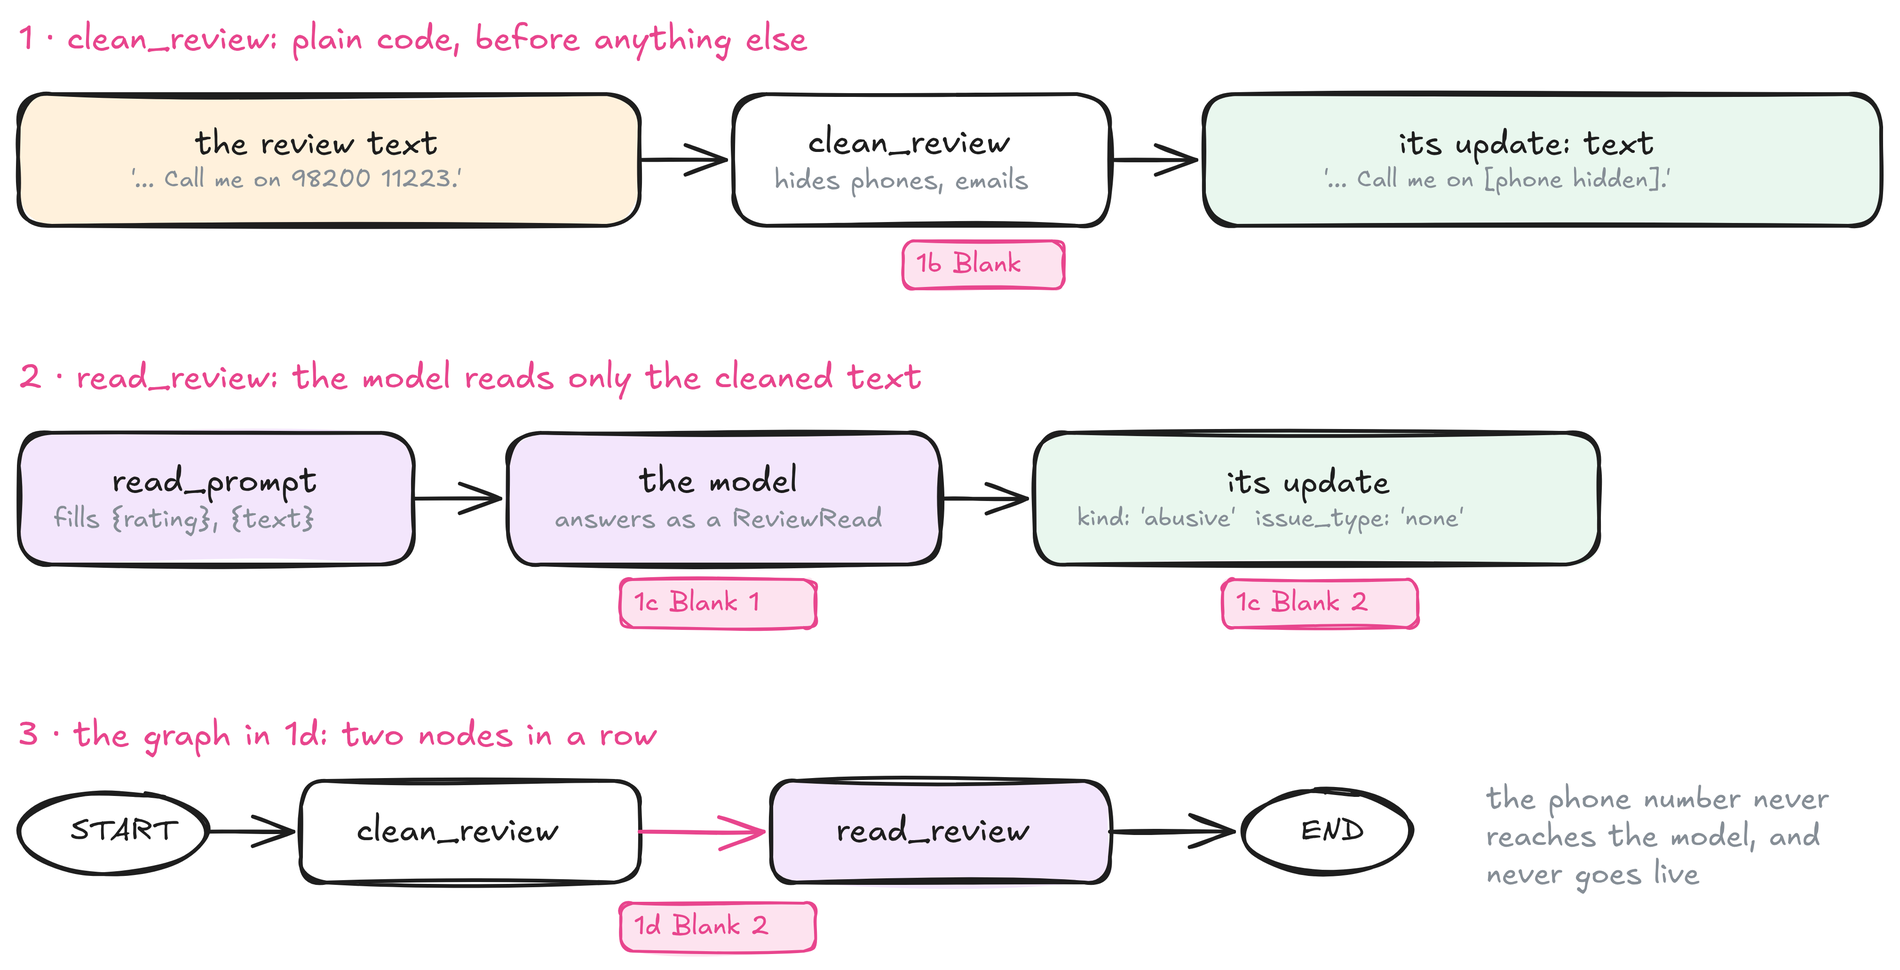

🛠️ **Your turn:** fill the 2 blanks in the next cell.

<table style="border-collapse:collapse;"><tr><td style="text-align:left;vertical-align:top;padding:4px 12px;white-space:nowrap;"><b>Blank 1</b></td><td style="text-align:left;vertical-align:top;padding:4px 12px;">the model, told to answer as a <code>ReviewRead</code>.</td></tr><tr><td style="text-align:left;vertical-align:top;padding:4px 12px;white-space:nowrap;"><b>Blank 2</b></td><td style="text-align:left;vertical-align:top;padding:4px 12px;">the update: <code>kind</code> and <code>issue_type</code>, from <code>result</code>.</td></tr></table>

<details><summary><b>Hint</b></summary>

- The model has a method that makes it reply in the shape of a Pydantic class. Its name starts with `with_`.
- A node returns a dict. `result` is a `ReviewRead`, so its fields are attributes: `result.something`.

</details>

In [200]:
# Part 1c: the shape of the answer, and the prompt
from pydantic import BaseModel, Field
from langchain_core.prompts import ChatPromptTemplate

class ReviewRead(BaseModel):
    kind: Literal["praise", "question", "complaint", "abusive"]
    issue_type: Literal["none", "size_fit", "quality_defect", "delivery", "other"] = Field(
        description="What a complaint is about; none for other kinds")

read_prompt = ChatPromptTemplate.from_messages([
    ("system", "You read product reviews for Hopscotch, a kids' clothing store."),
    ("human", "Rating: {rating} stars\nReview: {text}"),
])
print("System:", read_prompt.messages[0].prompt.template)
print("Human:", read_prompt.messages[1].prompt.template)
# print("System:", messages[0].content)
# print("Human:", messages[1].content)

System: You read product reviews for Hopscotch, a kids' clothing store.
Human: Rating: {rating} stars
Review: {text}


In [201]:
# Part 1c: the node
reader = read_prompt | llm.with_structured_output(ReviewRead)

def read_review(state: ReviewState):
    result = reader.invoke({"rating": state["review"]["rating"], "text": state["text"]})
    return {"kind": result.kind, "issue_type": result.issue_type}                                        # 🛠️ Blank 2

In [202]:
# Part 1b: clean_review
PHONE = re.compile(r"(\+91[\s-]?)?\b\d{5}\s?\d{5}\b")
EMAIL = re.compile(r"\S+@\S+\.\w+")
#LINK = re.compile(r"https?://|www\.", re.IGNORECASE)
LINK = re.compile(r"(?:https?://|www\.)\S+", re.IGNORECASE)

def clean_review(state: ReviewState):
    text = state["review"]["text"]
    text = PHONE.sub("[phone hidden]", text)
    text = EMAIL.sub("[EMAIL hidden]", text)
    text = LINK.sub("[Link hidden]", text)                     # 🛠️ Blank 1
    return {"text": text}

clean_review({"review": REVIEWS[4]})
print(clean_review({"review": REVIEWS[5]}))   


{'text': 'Great deals on kids wear at [Link hidden]'}


### 1d. Two nodes in a row

> **Key idea:** build a graph in 4 steps: create it, `add_node`, `add_edge`, `compile`. `add_edge("a", "b")` means: after `a`, always run `b`.

🛠️ **Your turn:** fill the 2 blanks in the next cell.

<table style="border-collapse:collapse;"><tr><td style="text-align:left;vertical-align:top;padding:4px 12px;white-space:nowrap;"><b>Blank 1</b></td><td style="text-align:left;vertical-align:top;padding:4px 12px;">add the node <code>"read_review"</code>.</td></tr><tr><td style="text-align:left;vertical-align:top;padding:4px 12px;white-space:nowrap;"><b>Blank 2</b></td><td style="text-align:left;vertical-align:top;padding:4px 12px;">the edge from <code>"clean_review"</code> to <code>"read_review"</code>.</td></tr></table>

<details><summary><b>Hint</b></summary>

- Copy the shape of the `add_node` line above it: a name, then the function.
- An edge goes from one node name to another. The `START` edge just above shows the pattern.

</details>

In [203]:
# Part 1d: START -> clean_review -> read_review -> END
from langgraph.graph import StateGraph, START, END

graph = StateGraph(ReviewState)
graph.add_node("clean_review", clean_review)
graph.add_node("read_review", read_review)          # 🛠️ Blank 1
graph.add_edge(START, "clean_review")
graph.add_edge("clean_review", "read_review")       # 🛠️ Blank 2
graph.add_edge("read_review", END)
app = graph.compile()
final = app.invoke({"review": REVIEWS[4]})
final

{'review': {'review_id': 'R-5',
  'sku': 'HS-412',
  'rating': 1,
  'text': 'Worst shoes ever, you idiots. Call me on 98200 11223.'},
 'text': 'Worst shoes ever, you idiots. Call me on [phone hidden].',
 'kind': 'abusive',
 'issue_type': 'none',
 'messages': []}

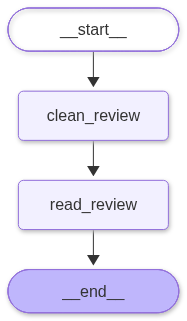

In [204]:
# Draw the graph you just built
show(app)

In [205]:
# ✅ Checks your work. Just run it.

check("The phone number is hidden", "98200" not in final["text"])
check("R-5 is abusive", final.get("kind") == "abusive", final.get("kind"))
check("R-2 is a question", app.invoke({"review": REVIEWS[1]}).get("kind") == "question")
# check("R-3 is a complaint", app.invoke({"review": REVIEWS[3]}).get("kind")== "complaint")

✅ The phone number is hidden
✅ R-5 is abusive
✅ R-2 is a question


**Now think about**
- Each node returned only its own keys, but `final` also has `review`. Why? <details><summary>Sample answer</summary>A node returns an **update**; LangGraph merges it into the state it already had.</details>
- What would the model see if the edge went the other way, `read_review` first? <details><summary>Sample answer</summary>The raw text, phone number included. The order of the edges is part of the privacy rule.</details>

**To further explore:** Docs: [LangGraph graph API: state, nodes, edges](https://docs.langchain.com/oss/python/langgraph/graph-api) · Guide: [Structured output](https://python.langchain.com/docs/how_to/structured_output/) · Video: [LangChain Academy: Introduction to LangGraph (free)](https://academy.langchain.com/courses/intro-to-langgraph)

<div style="background:#020B21;color:#FFFFFF;padding:12px 16px;border-left:6px solid #EC458D;border-radius:6px;"><span style="color:#FFCA8B;font-size:12px;letter-spacing:1px;">PART 2 OF 7</span><br><span style="font-size:20px;font-weight:700;">Triage: one router, four lanes</span><br><span style="color:#D451FF;font-size:13px;">A router function · add_conditional_edges · placeholders</span></div>

> **Key idea:** a **router** is a small function that looks at the state and returns the **name of the next node**. `add_conditional_edges` puts it after a node.

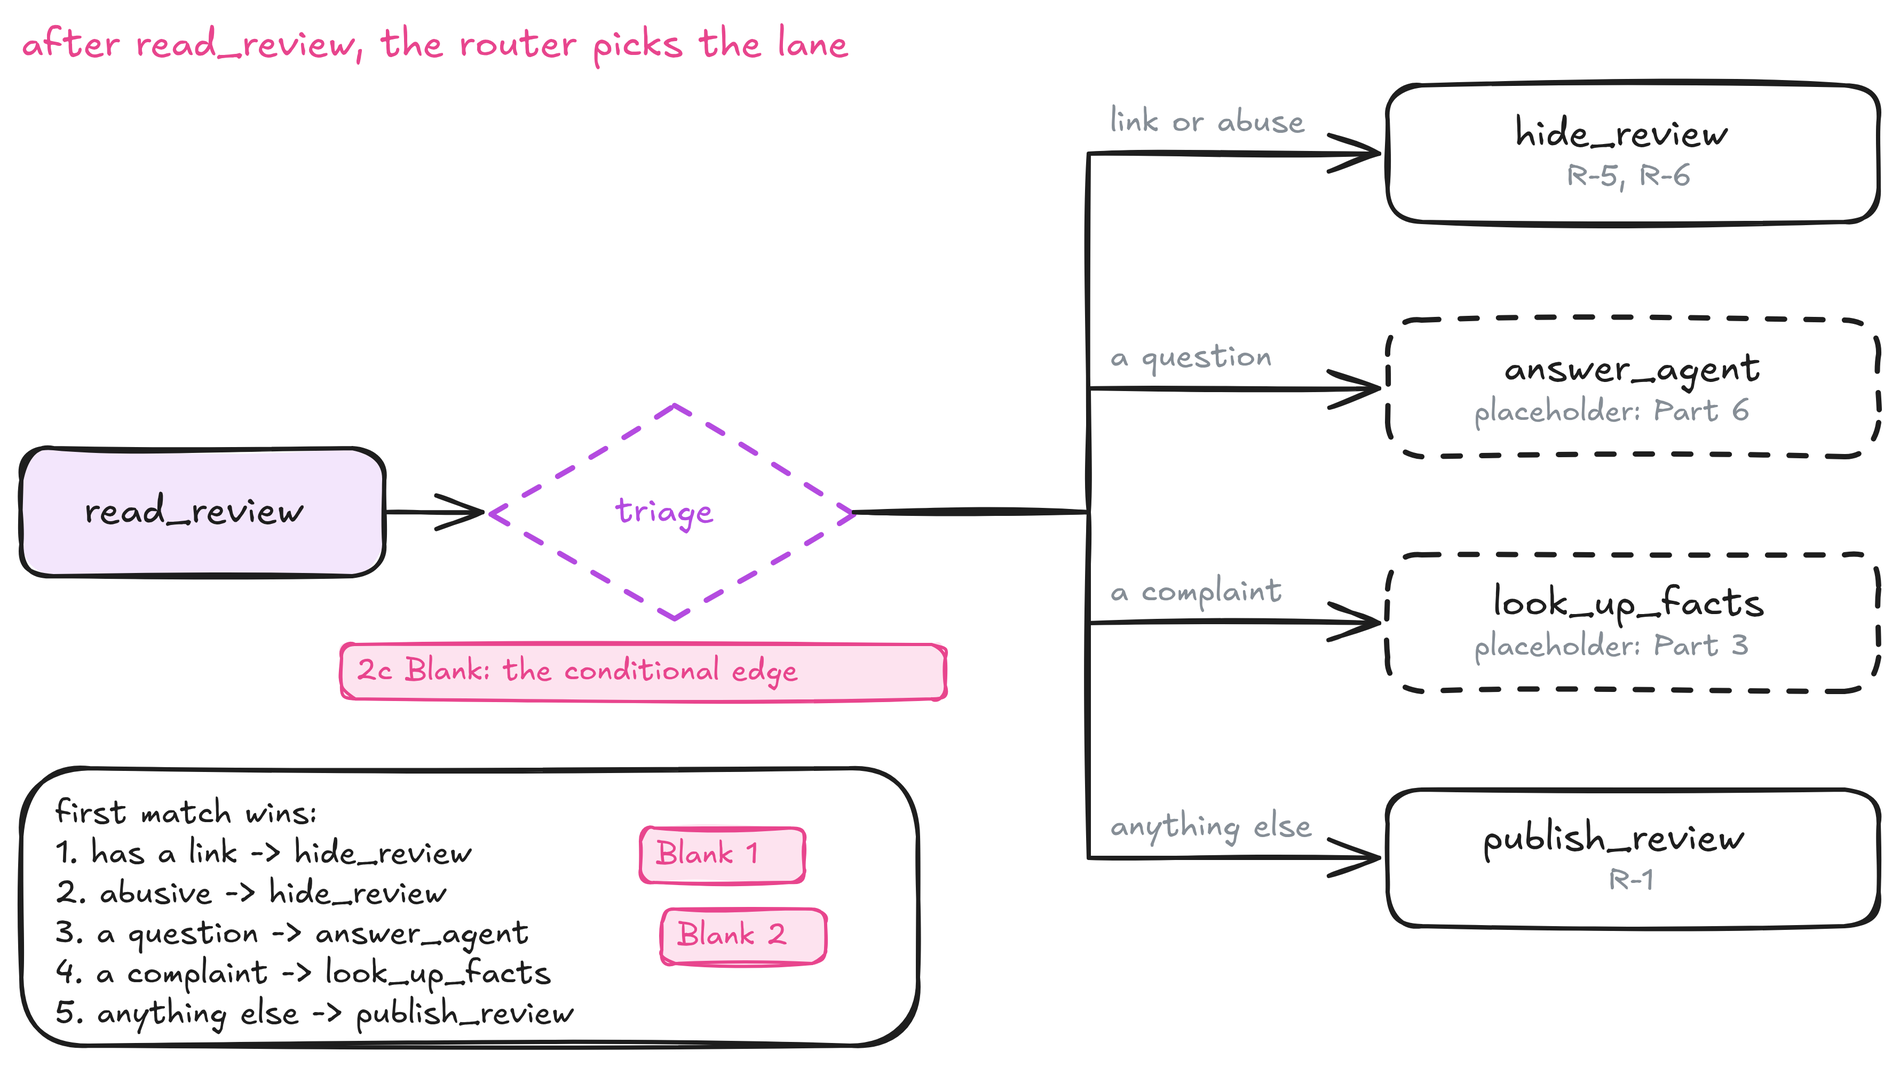

🛠️ **Your turn:** fill the 2 blanks in the next cell.

<table style="border-collapse:collapse;"><tr><td style="text-align:left;vertical-align:top;padding:4px 12px;white-space:nowrap;"><b>Blank 1</b></td><td style="text-align:left;vertical-align:top;padding:4px 12px;">rule 1: a review with a link is spam: hide it.</td></tr><tr><td style="text-align:left;vertical-align:top;padding:4px 12px;white-space:nowrap;"><b>Blank 2</b></td><td style="text-align:left;vertical-align:top;padding:4px 12px;">rule 3: a question goes to <code>"answer_agent"</code>.</td></tr></table>

<details><summary><b>Hint</b></summary>

- `LINK` is the pattern from Part 1b. Its `.search()` finds a match anywhere in a string.
- Rule 2, the abusive one, has exactly the shape you need for rule 3.

</details>

In [206]:
# Part 2a: the router, plain code (first match wins)
def triage(state: ReviewState):
    if state["kind"] == "question":
        return "answer_agent"                                              # 🛠️ Blank 1
    if state["kind"] == "abusive":
        return "hide_review"
    if state["kind"] == "complaint":                                       # 🛠️ Blank 2
        return "look_up_facts"
    return "publish_review"

The lane ends (given). `PUBLISHED` and `MODERATION_QUEUE` stand in for the website. The last two are **placeholders**, so the graph runs before Parts 3 and 6 build the real lanes.

In [207]:
# Part 2b: the lane ends
MODERATION_QUEUE, PUBLISHED = [], []

def hide_review(state: ReviewState):
    reason = "spam link" if LINK.search(state["text"]) else "abuse"
    MODERATION_QUEUE.append(state["review"]["review_id"])
    return {"status": f"hidden: {reason}"}

def publish_review(state: ReviewState):
    entry = {"review_id": state["review"]["review_id"], "text": state["text"]}
    for k in ["reply", "answer"]:              # Hopscotch's response, if any
        if state.get(k):
            entry[k] = state[k]
    PUBLISHED.append(entry)
    return {"status": "published"}

In [208]:
# Part 2b: placeholders, replaced in Parts 3 and 6
def answer_agent(state: ReviewState):
    return {"status": "question lane (Part 6)"}

def look_up_facts(state: ReviewState):
    return {"status": "complaint lane (Part 3)"}

🛠️ **Your turn:** fill the blank in the next cell.

<table style="border-collapse:collapse;"><tr><td style="text-align:left;vertical-align:top;padding:4px 12px;white-space:nowrap;"><b>Blank 1</b></td><td style="text-align:left;vertical-align:top;padding:4px 12px;">after <code>"read_review"</code>, call <code>triage</code>. It can go to any of <code>LANES</code>.</td></tr></table>

<details><summary><b>Hint</b></summary>

- `add_conditional_edges` takes 3 things: the node it comes after, the router, and the list of places it can go.

</details>

In [209]:
# Part 2c: the spine and the four lanes
LANES = ["hide_review", "publish_review", "answer_agent", "look_up_facts"]

graph = StateGraph(ReviewState)
graph.add_node("clean_review", clean_review)
graph.add_node("read_review", read_review)
graph.add_node("hide_review", hide_review)
graph.add_node("publish_review", publish_review)
graph.add_node("answer_agent", answer_agent)
graph.add_node("look_up_facts", look_up_facts)

graph.add_edge(START, "clean_review")
graph.add_edge("clean_review", "read_review")
graph.add_conditional_edges(
    "read_review",
    triage,
    {
        "answer_agent": "answer_agent",
        "publish_review": "publish_review",
        "look_up_facts": "look_up_facts",
        "hide_review": "hide_review",
    },
)
for lane in LANES:
    graph.add_edge(lane, END)
app = graph.compile()

results = {r["review_id"]: app.invoke({"review": r}) for r in REVIEWS}
for rid, f in results.items():
    print(rid, "|", f["kind"], "|", f["status"])

R-1 | praise | published
R-2 | question | question lane (Part 6)
R-3 | complaint | complaint lane (Part 3)
R-4 | complaint | complaint lane (Part 3)
R-5 | abusive | hidden: abuse
R-6 | praise | published
R-7 | question | question lane (Part 6)


In [210]:
# ✅ Checks your work. Just run it.

s = {rid: f["status"] for rid, f in results.items()}
check("R-6 (spam) and R-5 (abuse) are hidden",
      s["R-6"] == "hidden: spam link" and s["R-5"] == "hidden: abuse")
check("R-2 and R-7 go to the question lane", "question" in s["R-2"] and "question" in s["R-7"])
check("R-3 and R-4 go to the complaint lane", "complaint" in s["R-3"] and "complaint" in s["R-4"])
check("R-1 is published", s["R-1"] == "published")

❌ R-6 (spam) and R-5 (abuse) are hidden  
✅ R-2 and R-7 go to the question lane
✅ R-3 and R-4 go to the complaint lane
✅ R-1 is published


**Now think about**
- Why is the link rule **first**? What if a spam review were read as `"praise"` and the rule came last? <details><summary>Sample answer</summary>The first match wins: the praise rule would match first, and the spam would be **published**.</details>
- R-6 is spam, but it still cost a model call in `read_review`. How could you skip it? <details><summary>Sample answer</summary>Put a conditional edge right after `clean_review` that sends linked reviews straight to `hide_review`.</details>

**To further explore:** Docs: [Conditional edges](https://docs.langchain.com/oss/python/langgraph/graph-api#conditional-edges) · Guide: [Workflows and agents](https://docs.langchain.com/oss/python/langgraph/workflows-agents) · Video: [LangChain Academy: Introduction to LangGraph (free)](https://academy.langchain.com/courses/intro-to-langgraph)

<div style="background:#020B21;color:#FFFFFF;padding:12px 16px;border-left:6px solid #EC458D;border-radius:6px;"><span style="color:#FFCA8B;font-size:12px;letter-spacing:1px;">PART 3 OF 7</span><br><span style="font-size:20px;font-weight:700;">The complaint lane: three lookups at once</span><br><span style="color:#D451FF;font-size:13px;">Plain-code nodes · parallel branches · a join · a router that returns a list</span></div>

One complaint is a data point; six about the same batch is a bad batch. So each complaint gets 3 facts, from 3 Hopscotch systems:

| Node | How it works | For R-3 (the frock) |
|---|---|---|
| `count_complaints` | looks up this product and issue type in `COMPLAINTS_14_DAYS` | 6 |
| `get_return_rate` | finds the product's batch, then returned ÷ sold × 100 | 64 ÷ 400 = 16.0% |
| `vendor_record` | finds the product's vendor, then its count in `VENDOR_ALERTS` | 2 |

Each one reads the product (`sku`) from the state and writes one number back.

Every complaint needs the **same** 3 facts, so these are plain code, not tools.

In [211]:
# Part 3a: made-up data, standing in for Hopscotch's databases

# which vendor made each product, and in which batch
PRODUCTS = {
    "HS-118": {"vendor_id": "V2", "batch_id": "B4"},
    "HS-201": {"vendor_id": "V3", "batch_id": "B7"},
    "HS-305": {"vendor_id": "V1", "batch_id": "B2"},
    "HS-412": {"vendor_id": "V4", "batch_id": "B9"},
}

# how many complaints each (product, issue) had in the last 14 days
COMPLAINTS_14_DAYS = {
    ("HS-201", "quality_defect"): 6,
    ("HS-305", "quality_defect"): 1,
    ("HS-118", "size_fit"): 3,
}

# units sold and returned, per batch
BATCH_SALES = {
    "B4": {"sold": 800, "returned": 40},
    "B7": {"sold": 400, "returned": 64},
    "B2": {"sold": 600, "returned": 18},
    "B9": {"sold": 300, "returned": 9},
}

# quality alerts each vendor already had in the last 90 days
VENDOR_ALERTS = {"V1": 0, "V2": 1, "V3": 2, "V4": 0}

🛠️ **Your turn:** fill the blank in the next cell.

<table style="border-collapse:collapse;"><tr><td style="text-align:left;vertical-align:top;padding:4px 12px;white-space:nowrap;"><b>Blank 1</b></td><td style="text-align:left;vertical-align:top;padding:4px 12px;"><code>vendor_record</code>'s update: <code>VENDOR_ALERTS</code> for this vendor, under <code>vendor_alerts</code>.</td></tr></table>

<details><summary><b>Hint</b></summary>

- Look at what the two lookups above return: a dict with one key.
- `VENDOR_ALERTS` is a dict keyed by vendor, and `vendor` is already worked out for you.

</details>

In [212]:
# Part 3a: three lookups (each sleep stands in for a call to another system)
def count_complaints(state: ReviewState):
    time.sleep(0.5)
    pair = (state["review"]["sku"], state["issue_type"])
    return {"complaint_count": COMPLAINTS_14_DAYS.get(pair, 0)}   # 0 if none on record

def get_return_rate(state: ReviewState):
    time.sleep(0.5)
    batch = PRODUCTS[state["review"]["sku"]]["batch_id"]
    sales = BATCH_SALES[batch]
    return {"return_rate": round(sales["returned"] / sales["sold"] * 100, 1)}

def vendor_record(state: ReviewState):
    time.sleep(0.5)
    vendor = PRODUCTS[state["review"]["sku"]]["vendor_id"]
    return {"vendor_alerts": VENDOR_ALERTS[vendor]}                                       # 🛠️ Blank 1

LOOKUPS = ["count_complaints", "get_return_rate", "vendor_record"]
LOOKUP_NODES = {"count_complaints": count_complaints, "get_return_rate": get_return_rate,
                "vendor_record": vendor_record}

In [213]:
test_state = {
    "review": REVIEWS[0],          # R-3: product HS-201
    "issue_type": "quality_defect",
}

for name, function in LOOKUP_NODES.items():
    result = function(test_state)
    print(name, "->", result)

count_complaints -> {'complaint_count': 0}
get_return_rate -> {'return_rate': 5.0}
vendor_record -> {'vendor_alerts': 1}


### 3b. In a row, or all at once?

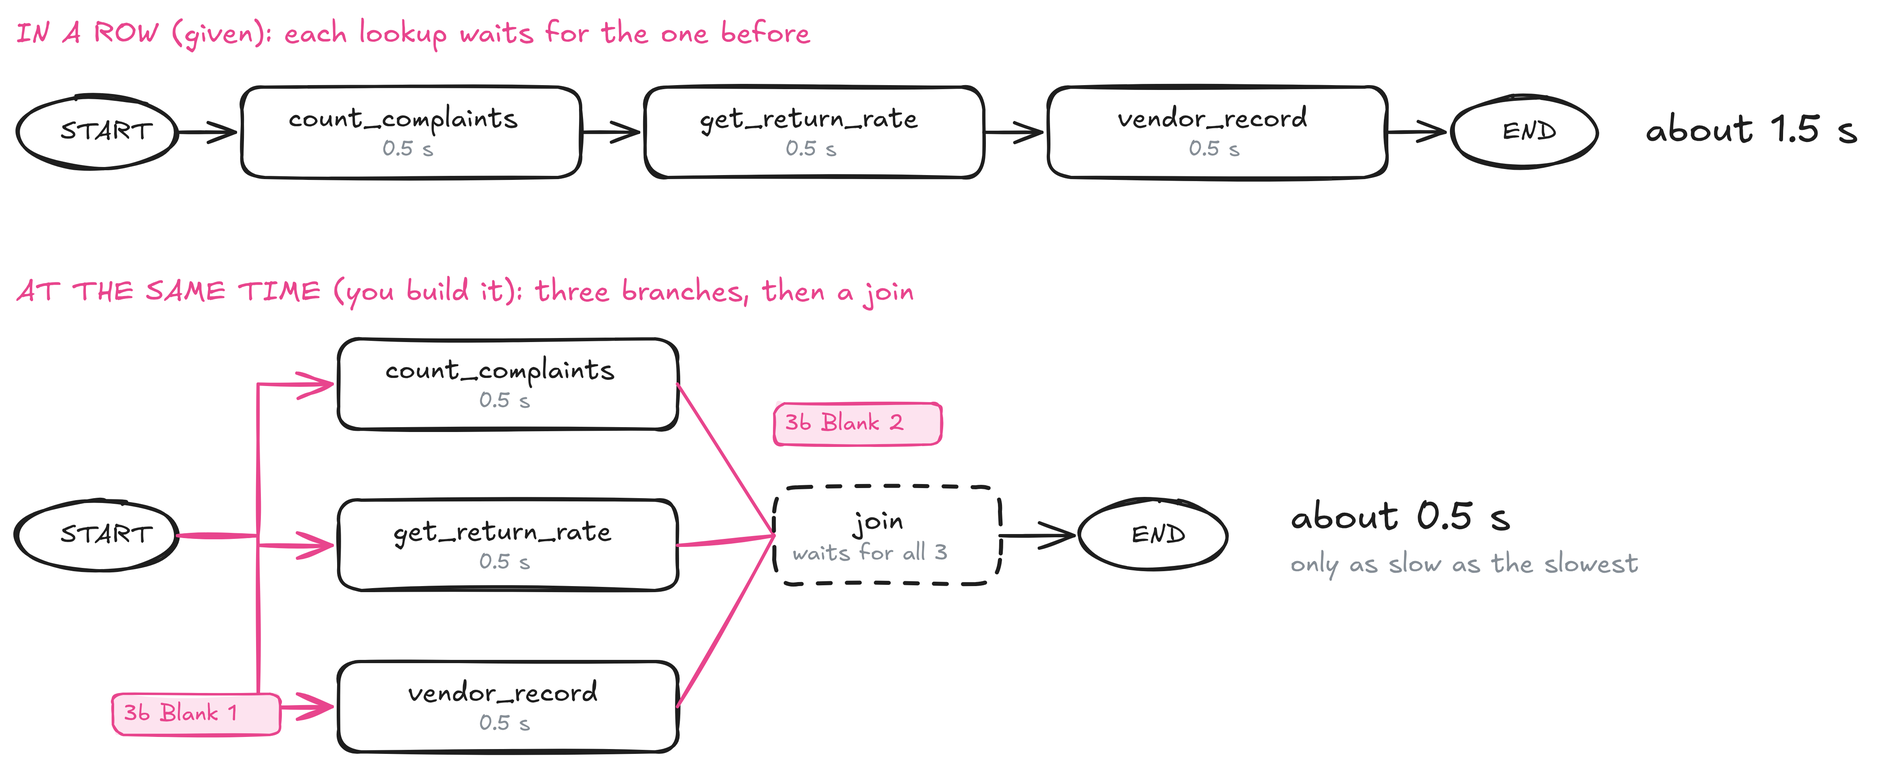

> **Key idea:** when one node has edges to several nodes, they run **at the same time**. `add_edge(["a", "b", "c"], "next")` is a **join**: `next` waits for all of them.

First, the given version: in a row.

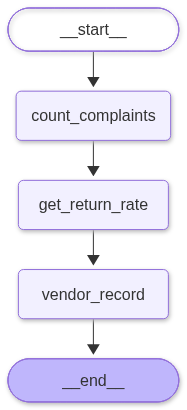

in a row: 1.5 s


In [214]:
# Part 3b (given): one after another
in_a_row = StateGraph(ReviewState)
for name, fn in LOOKUP_NODES.items():
    in_a_row.add_node(name, fn)
in_a_row.add_edge(START, "count_complaints")
in_a_row.add_edge("count_complaints", "get_return_rate")
in_a_row.add_edge("get_return_rate", "vendor_record")
in_a_row.add_edge("vendor_record", END)
slow_lane = in_a_row.compile()
show(slow_lane)

complaint = {"review": REVIEWS[2], "issue_type": "quality_defect"}
start = time.time(); 
slow_lane.invoke(complaint)
print(f"in a row: {time.time() - start:.1f} s")

🛠️ **Your turn:** fill the 2 blanks in the next cell.

<table style="border-collapse:collapse;"><tr><td style="text-align:left;vertical-align:top;padding:4px 12px;white-space:nowrap;"><b>Blank 1</b></td><td style="text-align:left;vertical-align:top;padding:4px 12px;">the third branch, from <code>START</code> to <code>"vendor_record"</code>.</td></tr><tr><td style="text-align:left;vertical-align:top;padding:4px 12px;white-space:nowrap;"><b>Blank 2</b></td><td style="text-align:left;vertical-align:top;padding:4px 12px;">the join: from all of <code>LOOKUPS</code> to <code>END</code>.</td></tr></table>

<details><summary><b>Hint</b></summary>

- The two lines above it are the first two branches.
- A join is still `add_edge`. Its first argument can be a list of node names, and you already have one.

</details>

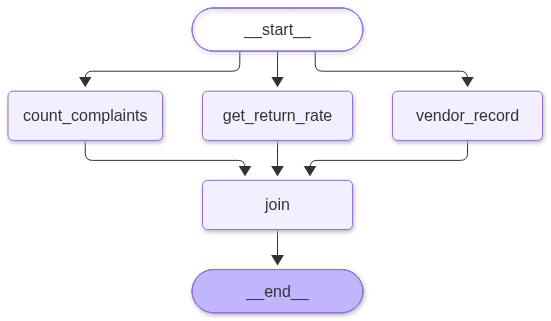

at once: 0.5 s


In [215]:
# Part 3b: all at once
at_once = StateGraph(ReviewState)
for name, fn in LOOKUP_NODES.items():
    at_once.add_node(name, fn)
at_once.add_edge(START, "count_complaints")
at_once.add_edge(START, "get_return_rate")
at_once.add_edge(START, "vendor_record")                                                   # 🛠️ Blank 1
def join(state: ReviewState):
    return {}

at_once.add_node("join", join)

# Wait for all three nodes before running join.
at_once.add_edge(
    ["count_complaints", "get_return_rate", "vendor_record"],
    "join"
)
at_once.add_edge("join", END) 
                                                                                       # 🛠️ Blank 2
fast_lane = at_once.compile()
show(fast_lane)  

start = time.time(); facts = fast_lane.invoke(complaint)
print(f"at once: {time.time() - start:.1f} s")

In [216]:
# ✅ Checks your work. Just run it.

found = [facts.get(k) for k in ["complaint_count", "return_rate", "vendor_alerts"]]
check("R-3: 6 complaints, 16% returns, 2 vendor alerts", found == [6, 16.0, 2], found)
start = time.time(); fast_lane.invoke(complaint)
check("At once takes about 0.5 s, not 1.5 s", time.time() - start < 1.2)

✅ R-3: 6 complaints, 16% returns, 2 vendor alerts
✅ At once takes about 0.5 s, not 1.5 s


### 3c. Start the lane from the router

A router can return a **list** of node names: LangGraph starts them all at once.

🛠️ **Your turn:** fill the blank in the next cell.

<table style="border-collapse:collapse;"><tr><td style="text-align:left;vertical-align:top;padding:4px 12px;white-space:nowrap;"><b>Blank 1</b></td><td style="text-align:left;vertical-align:top;padding:4px 12px;">for a complaint, return all 3 lookups at once.</td></tr></table>

<details><summary><b>Hint</b></summary>

- A router can return a list of node names instead of one name. Is there a list from Part 3a you could use?

</details>

In [239]:
# Part 3c: triage, now starting the 3 lookups
def triage(state: ReviewState):
    if LINK.search(state["text"]) or state["kind"] == "abusive":
        return "hide_review"
    if state["kind"] == "question":
        return "answer_agent"
    if state["kind"] == "complaint":
        return LOOKUPS                                    # 🛠️ Blank 1
    return "publish_review"

In [240]:
# ✅ Checks your work. Just run it.

r3 = {"review": REVIEWS[2], "text": REVIEWS[2]["text"], "kind": "complaint"}
check("A complaint starts all 3 lookups", triage(r3) == LOOKUPS)

✅ A complaint starts all 3 lookups


**Now think about**
- All 3 lookups write to the state in the same step. Why is that safe here? <details><summary>Sample answer</summary>Each writes **its own key**. Two parallel nodes writing the same plain key would raise an `InvalidUpdateError`.</details>
- Part 5 gives the model **tools**. Why are these lookups plain code instead? <details><summary>Sample answer</summary>Every complaint needs the same 3 facts: there is no choice to make, so no model is needed.</details>

**To further explore:** Docs: [Run branches in parallel](https://docs.langchain.com/oss/python/langgraph/use-graph-api#create-branches) · Guide: [Parallel execution in LangGraph](https://machinelearningplus.com/gen-ai/langgraph-map-reduce-parallel-execution/) · Video: [LangChain Academy: Introduction to LangGraph (free)](https://academy.langchain.com/courses/intro-to-langgraph)

<div style="background:#020B21;color:#FFFFFF;padding:12px 16px;border-left:6px solid #EC458D;border-radius:6px;"><span style="color:#FFCA8B;font-size:12px;letter-spacing:1px;">PART 4 OF 7</span><br><span style="font-size:20px;font-weight:700;">The reply and the alert</span><br><span style="color:#D451FF;font-size:13px;">A model node that writes twice · a join into one node</span></div>

Complaints are published: hiding honest negative reviews breaks trust (and India's review standard, IS 19000). Instead, one node writes:

- a **reply** under the review, for other parents
- an **alert** for the quality team, with the 3 facts as evidence

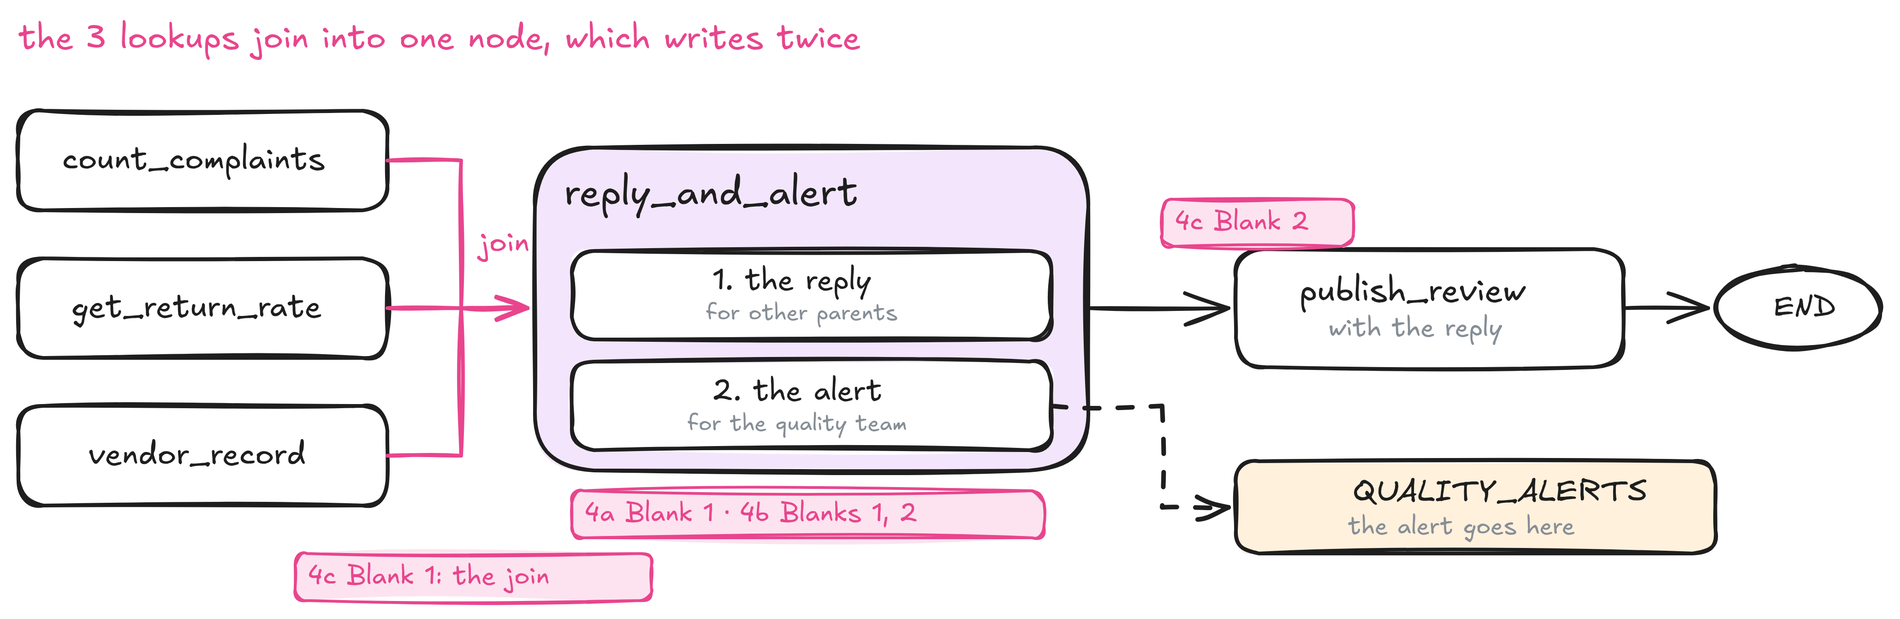

In [241]:
# Part 4a (given): the reply writer
from langchain_core.output_parsers import StrOutputParser

REPLY_RULES = """Say sorry and thank them. Say it is passed on to the quality team.
Never promise a refund or discount: returns go through the Orders page. Under 50 words."""

reply_prompt = ChatPromptTemplate.from_messages([
    ("system", "You write Hopscotch's public replies to complaints. Rules:\n" + REPLY_RULES),
    ("human", "Review ({rating} stars): {text}"),
])
reply_writer = reply_prompt | llm | StrOutputParser()

🛠️ **Your turn:** fill the blank in the next cell.

<table style="border-collapse:collapse;"><tr><td style="text-align:left;vertical-align:top;padding:4px 12px;white-space:nowrap;"><b>Blank 1</b></td><td style="text-align:left;vertical-align:top;padding:4px 12px;">the alert writer's instruction, in your own words, <b>under 40 words</b>: a 2-sentence alert for the quality team that names the product and the problem, uses the evidence, and suggests one next step.</td></tr></table>

<details><summary><b>Hint</b></summary>

- Say who the reader is, how long it should be, and what it must include. Then count: under 40 words.
- Look at `REPLY_RULES` above for the style of instruction that works.

</details>

In [264]:
# Part 4a: the alert writer
ALERT_INSTRUCTION = """
write_alert , and add a plain
spike_rule (5+ complaints or 12%+
returns). The alert is written only on a spike. 
an alert for the quality team with the 3 facts.  
Under 50 words."""
                                                                                                                # 🛠️ Blank 1

alert_prompt = ChatPromptTemplate.from_messages([
    ("system", ALERT_INSTRUCTION),
    ("human", "Product: {sku}\nReview: {text}\nEvidence: {evidence}"),
])
alert_writer = alert_prompt | llm | StrOutputParser()
QUALITY_ALERTS = []

🛠️ **Your turn:** fill the 2 blanks in the next cell.

<table style="border-collapse:collapse;"><tr><td style="text-align:left;vertical-align:top;padding:4px 12px;white-space:nowrap;"><b>Blank 1</b></td><td style="text-align:left;vertical-align:top;padding:4px 12px;">the evidence line: the 3 facts in one string.</td></tr><tr><td style="text-align:left;vertical-align:top;padding:4px 12px;white-space:nowrap;"><b>Blank 2</b></td><td style="text-align:left;vertical-align:top;padding:4px 12px;">the update: the reply, under <code>reply</code>.</td></tr></table>

<details><summary><b>Hint</b></summary>

- An f-string can put values from the state into a sentence: `f"... {state['some_key']} ..."`. Which 3 keys did Part 3 fill?
- The node changes one key in the state. What is it called, and which variable holds it?

</details>

In [265]:
# Part 4b: the node
def reply_and_alert(state: ReviewState):
    reply = reply_writer.invoke({"rating": state["review"]["rating"], "text": state["text"]})

    evidence = (
        f"Complaints for this product and issue in the last 14 days: "
        f"{state['complaint_count']}. "
        f"Batch return rate: {state['return_rate']}%. "
        f"Vendor quality alerts in the last 90 days: "
        f"{state['vendor_alerts']}."
    )                                   # 🛠️ Blank 1
    alert = alert_writer.invoke({"sku": state["review"]["sku"], "text": state["text"],
                                 "evidence": evidence})
    QUALITY_ALERTS.append({"sku": state["review"]["sku"], "alert": alert})
    print("\nCustomer reply:", reply)
    print("\nQuality alert:", alert)

    

    # Blank 2: save the reply for publish_review
    return {"reply": reply}                                    # 🛠️ Blank 2

In [244]:
test_state = {
    "review": REVIEWS[2],
    "text": REVIEWS[2]["text"],
    "complaint_count": 6,
    "return_rate": 16.0,
    "vendor_alerts": 2,
}

result = reply_and_alert(test_state)
print("\nReturned update:", result)


Customer reply: We're sorry to hear about your experience with the colors bleeding. Thank you for bringing this to our attention; we’ve passed your feedback on to our quality team for review.

Quality alert: **Alert for Quality Team:**  
Spike detected for product HS-201:  
- 6 complaints regarding color bleeding.  
- 16% return rate exceeds threshold.  
- 2 vendor quality alerts in the last 90 days.  
Immediate investigation required.

Returned update: {'reply': "We're sorry to hear about your experience with the colors bleeding. Thank you for bringing this to our attention; we’ve passed your feedback on to our quality team for review."}


### 4c. The whole complaint lane

🛠️ **Your turn:** fill the 2 blanks in the next cell.

<table style="border-collapse:collapse;"><tr><td style="text-align:left;vertical-align:top;padding:4px 12px;white-space:nowrap;"><b>Blank 1</b></td><td style="text-align:left;vertical-align:top;padding:4px 12px;">the join: from all of <code>LOOKUPS</code> to <code>"reply_and_alert"</code>.</td></tr><tr><td style="text-align:left;vertical-align:top;padding:4px 12px;white-space:nowrap;"><b>Blank 2</b></td><td style="text-align:left;vertical-align:top;padding:4px 12px;">then on to <code>"publish_review"</code>.</td></tr></table>

<details><summary><b>Hint</b></summary>

- This is the same join as in Part 3b, but it leads to a node instead of `END`.
- The second blank is an ordinary edge, from one node name to the next.

</details>

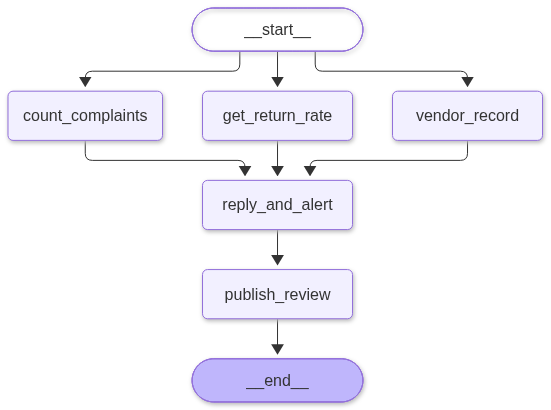


Customer reply: We're sorry to hear about the issue with the colors bleeding. Thank you for bringing this to our attention; we’ve passed your feedback on to our quality team for review.

Quality alert: **Alert for Quality Team:**  
Spike detected for product HS-201:  
- 6 complaints regarding color bleeding.  
- 16% return rate exceeds threshold.  
- 2 vendor quality alerts in the last 90 days.  
Immediate investigation required.
R-3 | reply: We're sorry to hear about the issue with the colors bleeding. Thank you for bringing this to our attention; we’ve passed your feedback on to our quality team for review.

Customer reply: We're sorry to hear about the strap button issue and appreciate your feedback. We've passed your comments on to our quality team for review. Thank you for bringing this to our attention!

Quality alert: **Alert for Quality Team:**  
Product HS-305 has received 5+ complaints regarding strap button issues in the last 14 days. Current batch return rate is 3.0%. No v

In [245]:
# Part 4c: START -> 3 lookups -> reply_and_alert -> publish_review -> END
lane = StateGraph(ReviewState)
for name, fn in LOOKUP_NODES.items():
    lane.add_node(name, fn)
    lane.add_edge(START, name)
lane.add_node("reply_and_alert", reply_and_alert)
lane.add_node("publish_review", publish_review)
# Wait for ALL three lookups
lane.add_edge(LOOKUPS, "reply_and_alert")
# lane.add_edge(START, reply_and_alert)                                                   # 🛠️ Blank 1
lane.add_edge("reply_and_alert", "publish_review")                                                   # 🛠️ Blank 2
lane.add_edge("publish_review", END)
complaint_lane = lane.compile()
show(complaint_lane)

QUALITY_ALERTS.clear(); PUBLISHED.clear()
for r in [REVIEWS[2], REVIEWS[3], REVIEWS[0]]:
    start_state = {"review": r, "text": r["text"], "issue_type": "quality_defect"}
    final = complaint_lane.invoke(start_state)
    print(r["review_id"], "| reply:", final["reply"])
print("alerts for:", [a["sku"] for a in QUALITY_ALERTS])

In [246]:
# ✅ Checks your work. Just run it.

alerts = [a["sku"] for a in QUALITY_ALERTS]
check("Both complaints raised an alert", alerts == ["HS-201", "HS-305"], alerts)
check("Both are published", [p["review_id"] for p in PUBLISHED] == ["R-3", "R-4"])
check("Each has a reply", all(p.get("reply") for p in PUBLISHED))
check("Your instruction is under 40 words", len(ALERT_INSTRUCTION.split()) < 40)

❌ Both complaints raised an alert  ['HS-201', 'HS-305', 'HS-118']
❌ Both are published  
✅ Each has a reply
✅ Your instruction is under 40 words


**Now think about**
- R-3 has 6 complaints and 16% returns; R-4 has 1 and 3%. Both raised an alert. What happens at 2,000 reviews a day? <details><summary>Sample answer</summary>The quality team drowns in alerts and misses the real bad batch. Alert only on a **spike**: that is **Exercise 1**.</details>
- Who should decide what counts as a spike: the model or plain code? <details><summary>Sample answer</summary>Plain code: it is a business rule, and the same facts must always give the same answer.</details>

**To further explore:** Guide: [Workflows and agents](https://docs.langchain.com/oss/python/langgraph/workflows-agents) · Docs: [LangGraph graph API: state, nodes, edges](https://docs.langchain.com/oss/python/langgraph/graph-api) · Video: [LangChain Academy: Introduction to LangGraph (free)](https://academy.langchain.com/courses/intro-to-langgraph)

<div style="background:#FFF6EA;border-left:6px solid #FFCA8B;padding:12px 16px;border-radius:6px;">
<b style="color:#EC458D;">Halfway.</b> Next: the question lane, then wire everything. If you take a break, <i>Run All</i> first when you come back.
</div>

<div style="background:#020B21;color:#FFFFFF;padding:12px 16px;border-left:6px solid #EC458D;border-radius:6px;"><span style="color:#FFCA8B;font-size:12px;letter-spacing:1px;">PART 5 OF 7</span><br><span style="font-size:20px;font-weight:700;">Tools: let the model choose what to look up</span><br><span style="color:#D451FF;font-size:13px;">@tool · bind_tools · tool_calls</span></div>

Each question needs **different** facts: R-2 needs care and stock; R-7 needs the size chart, **then** the stock. The model has to choose, so it gets **tools**.

> **Key idea:** a **tool** is a function the model can ask to run. It reads the name, arguments and docstring, then answers with a **tool call**.

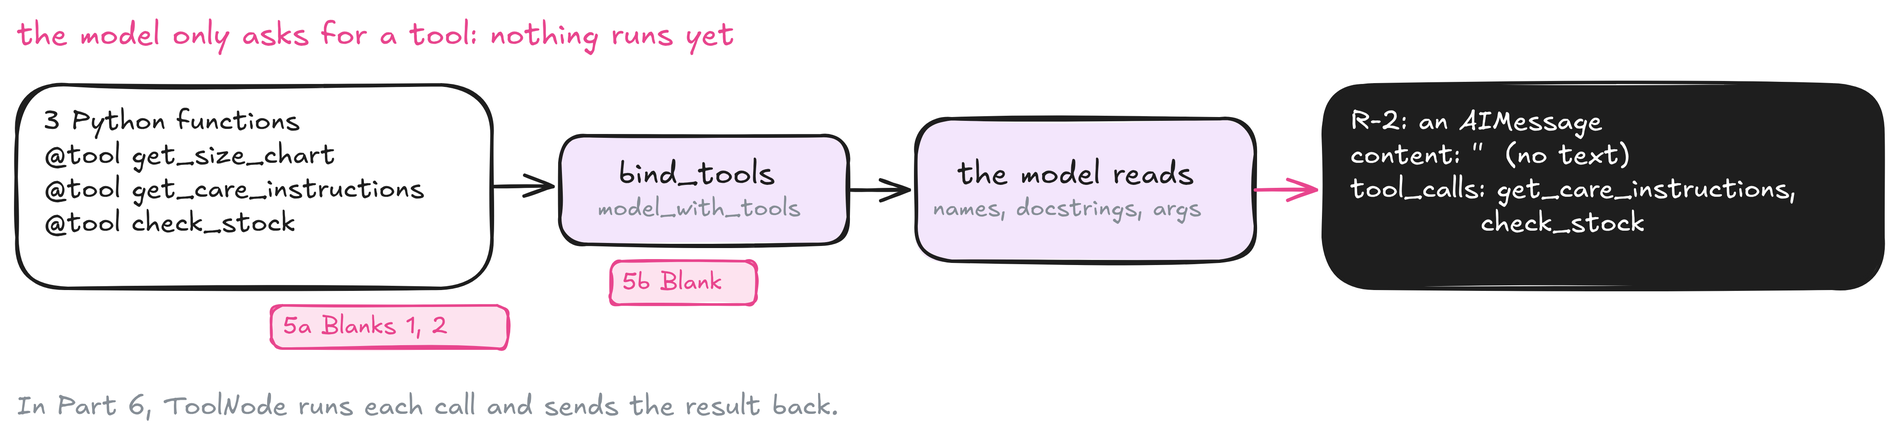

In [247]:
# Part 5a: the question data (made up)
SIZE_CHARTS = {"HS-118": {"3-4Y": "98-104 cm", "4-5Y": "104-110 cm", "5-6Y": "110-116 cm"},
               "HS-201": {"2-3Y": "92-98 cm", "3-4Y": "98-104 cm", "4-5Y": "104-110 cm"}}
CARE = {"HS-118": "Machine wash cold. Do not tumble dry.",
        "HS-201": "Machine wash cold, inside out, with similar colours."}
STOCK = {"HS-118": {"3-4Y": 14, "4-5Y": 9, "5-6Y": 0},
         "HS-201": {"2-3Y": 6, "3-4Y": 0, "4-5Y": 12}}

| Tool | The model passes | It returns | Example |
|---|---|---|---|
| `get_size_chart` | a product | each size and the heights it fits | HS-118 → 4-5Y fits 104-110 cm |
| `get_care_instructions` | a product | how to wash it | HS-201 → machine wash cold, inside out |
| `check_stock` | a product **and** a size | units in stock | HS-118, 4-5Y → 9 |

The model reads only each tool's name, arguments and docstring, so those must say what the tool is for.

🛠️ **Your turn:** fill the 2 blanks in the next cell.

<table style="border-collapse:collapse;"><tr><td style="text-align:left;vertical-align:top;padding:4px 12px;white-space:nowrap;"><b>Blank 1</b></td><td style="text-align:left;vertical-align:top;padding:4px 12px;">turn <code>check_stock</code> into a tool.</td></tr><tr><td style="text-align:left;vertical-align:top;padding:4px 12px;white-space:nowrap;"><b>Blank 2</b></td><td style="text-align:left;vertical-align:top;padding:4px 12px;">its docstring: what it returns, and what <code>size</code> looks like.</td></tr></table>

<details><summary><b>Hint</b></summary>

- Look at the line just above `def get_size_chart`.
- The model only sees this docstring. Write it for someone who has never seen `STOCK`: what comes back, and what a valid `size` looks like.

</details>

In [248]:
# Part 5a: three read-only tools
from langchain_core.tools import tool

@tool
def get_size_chart(sku: str) -> dict:
    """The size chart of a product: each size label (like 4-5Y) and the height it fits."""
    return SIZE_CHARTS.get(sku, {})

@tool
def get_care_instructions(sku: str) -> str:
    """How to wash and dry a product."""
    return CARE.get(sku, "unknown")

@tool                                                   # 🛠️ Blank 1
def check_stock(sku: str, size: str) -> dict:
    """Units in stock by product and its size """                                               # 🛠️ Blank 2
    return {"size": size, "in_stock": STOCK.get(sku, {}).get(size)}

TOOLS = [get_size_chart, get_care_instructions, check_stock]

### 5b. What a tool call looks like

🛠️ **Your turn:** fill the blank in the next cell.

<table style="border-collapse:collapse;"><tr><td style="text-align:left;vertical-align:top;padding:4px 12px;white-space:nowrap;"><b>Blank 1</b></td><td style="text-align:left;vertical-align:top;padding:4px 12px;">give the model the tools.</td></tr></table>

<details><summary><b>Hint</b></summary>

- The method's name says what it does: it binds the tools to the model. Pass it the list.

</details>

In [249]:
# Part 5b: one call, two questions
from langchain_core.messages import HumanMessage, AIMessage, SystemMessage

model_with_tools = llm.bind_tools(TOOLS)                                 # 🛠️ Blank 1

for r in [REVIEWS[1], REVIEWS[0], REVIEWS[2], REVIEWS[3], REVIEWS[6]]:
    ai = model_with_tools.invoke([HumanMessage(f"Product {r['sku']}: {r['text']}")])
    print(r["review_id"], "asks for:", [(c["name"], c["args"]) for c in ai.tool_calls])

R-2 asks for: [('get_care_instructions', {'sku': 'HS-201'}), ('check_stock', {'sku': 'HS-201', 'size': '4-5Y'})]
R-1 asks for: [('get_size_chart', {'sku': 'HS-118'}), ('get_care_instructions', {'sku': 'HS-118'}), ('check_stock', {'sku': 'HS-118', 'size': '4-5Y'})]
R-3 asks for: [('get_care_instructions', {'sku': 'HS-201'})]
R-4 asks for: [('get_care_instructions', {'sku': 'HS-305'})]
R-7 asks for: [('get_size_chart', {'sku': 'HS-118'})]


**Now think about**
- For R-7, did the model ask for `check_stock` yet? Why not? <details><summary>Sample answer</summary>Usually not: it cannot know which size fits 108 cm until it has seen the size chart.</details>
- Did any tool actually run? <details><summary>Sample answer</summary>No. The model only **asked**. Running tools and sending results back is the graph's job (Part 6).</details>

**To further explore:** Guide: [Tools and tool calling](https://python.langchain.com/docs/concepts/tools/) · Guide: [Workflows and agents](https://docs.langchain.com/oss/python/langgraph/workflows-agents) · Video: [DeepLearning.AI: AI Agents in LangGraph](https://www.deeplearning.ai/short-courses/ai-agents-in-langgraph)

<div style="background:#020B21;color:#FFFFFF;padding:12px 16px;border-left:6px solid #EC458D;border-radius:6px;"><span style="color:#FFCA8B;font-size:12px;letter-spacing:1px;">PART 6 OF 7</span><br><span style="font-size:20px;font-weight:700;">The question lane: the tool loop</span><br><span style="color:#D451FF;font-size:13px;">A reducer · the agent node · ToolNode · a loop with a cap</span></div>

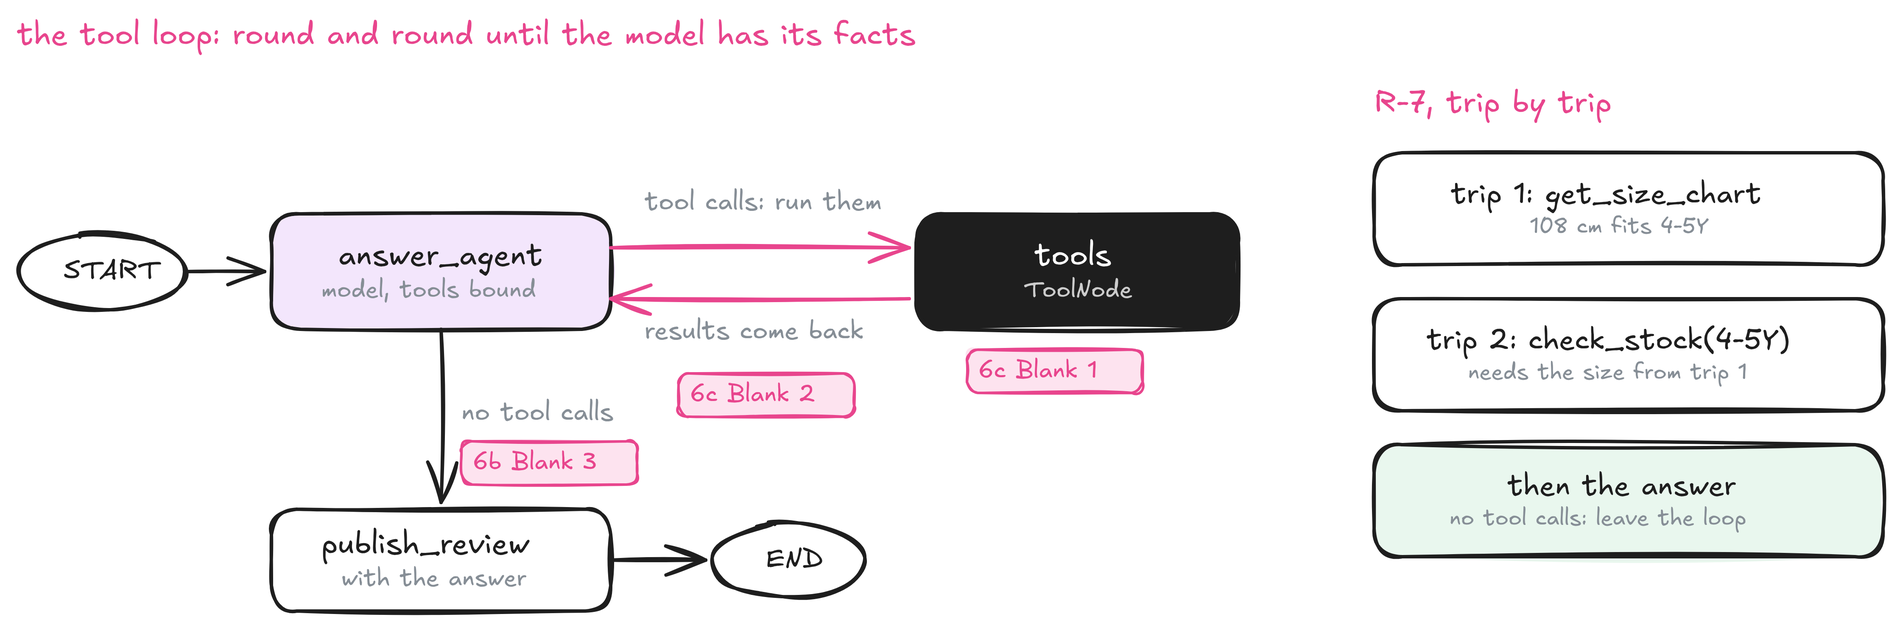

> **Key idea:** `answer_agent` asks for tools; `ToolNode` runs them and adds the results to `messages`; the graph goes **back** to the agent. No more tool calls: its reply is the answer.

### 6a. A reducer (given)

`messages` is `Annotated[list, operator.add]`: each update is **added** to the list, not swapped in.

In [250]:
# Part 6a: what the reducer does
before = [HumanMessage("which size for 108 cm?")]
update = [AIMessage("asks for get_size_chart")]
print("plain key:", [m.content for m in update])
print("reducer:  ", [m.content for m in operator.add(before, update)])

plain key: ['asks for get_size_chart']
reducer:   ['which size for 108 cm?', 'asks for get_size_chart']


### 6b. The agent and its router

🛠️ **Your turn:** fill the 3 blanks in the next cell.

<table style="border-collapse:collapse;"><tr><td style="text-align:left;vertical-align:top;padding:4px 12px;white-space:nowrap;"><b>Blank 1</b></td><td style="text-align:left;vertical-align:top;padding:4px 12px;">if the model asked for tools, add 1 to <code>trips</code>.</td></tr><tr><td style="text-align:left;vertical-align:top;padding:4px 12px;white-space:nowrap;"><b>Blank 2</b></td><td style="text-align:left;vertical-align:top;padding:4px 12px;">otherwise, the model's reply is the answer: store its text in <code>update</code>, under <code>answer</code>.</td></tr><tr><td style="text-align:left;vertical-align:top;padding:4px 12px;white-space:nowrap;"><b>Blank 3</b></td><td style="text-align:left;vertical-align:top;padding:4px 12px;">the way out: no tool calls left means go to <code>"publish_review"</code>.</td></tr></table>

<details><summary><b>Hint</b></summary>

- `response.tool_calls` is an empty list when the model asked for nothing, and an empty list counts as `False` in an `if`.
- The text of a message is in its `.content`. Add it to `update`, under the right key.
- The newest message is the last one in `state["messages"]`. Did it ask for any tools?

</details>

In [251]:
# Part 6b: the agent's rules (given)
AGENT_RULES = """You answer customers' questions in Hopscotch reviews.
Use the tools for facts; never guess. Ask for independent tools together.
When you have the facts, reply with the answer only: friendly, under 50 words."""
MAX_TRIPS = 4

In [252]:
# Part 6b: the agent and its router
def answer_agent(state: ReviewState):
    question = HumanMessage(f"Product: {state['review']['sku']}\nReview: {state['text']}")
    history = [SystemMessage(AGENT_RULES), question] + state.get("messages", [])
    response = model_with_tools.invoke(history)

    update, trips = {"messages": [response]}, state.get("trips", 0)
    if response.tool_calls:
        trips += 1                                               # 🛠️ Blank 1
    else:
        update["answer"] = response.content                                                # 🛠️ Blank 2
    update["trips"] = trips
    return update

def after_agent(state: ReviewState):
    if not state["messages"][-1] . tool_calls:
            return "publish_review"            # the cap: publish without an answer
                                                     # 🛠️ Blank 3
    if state["trips"] > MAX_TRIPS:
        return "publish_review"            # the cap: publish without an answer
    return "tools"

### 6c. Wire the loop

🛠️ **Your turn:** fill the 2 blanks in the next cell.

<table style="border-collapse:collapse;"><tr><td style="text-align:left;vertical-align:top;padding:4px 12px;white-space:nowrap;"><b>Blank 1</b></td><td style="text-align:left;vertical-align:top;padding:4px 12px;">the node that runs the tools: <code>ToolNode</code>.</td></tr><tr><td style="text-align:left;vertical-align:top;padding:4px 12px;white-space:nowrap;"><b>Blank 2</b></td><td style="text-align:left;vertical-align:top;padding:4px 12px;">the edge back, from <code>"tools"</code> to <code>"answer_agent"</code>.</td></tr></table>

<details><summary><b>Hint</b></summary>

- `ToolNode` is imported at the top of the cell. It needs to know which tools it can run.
- A loop is just an edge that goes back to a node that has already run.

</details>

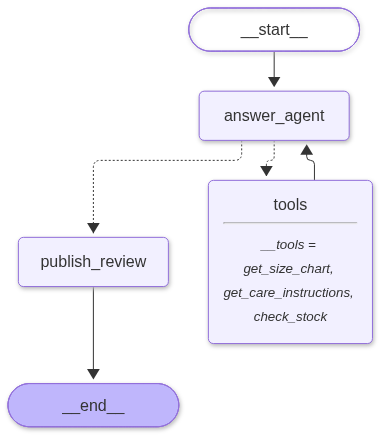

R-2 | trips: 1 | Yes, it's machine washable! The care instructions are to wash cold, inside out, with similar colors. Also, the 4-5Y size is in stock.
R-7 | trips: 1 | For your daughter at 108 cm, the size 4-5Y is recommended, and it is in stock!


In [253]:
# Part 6c: START -> answer_agent <-> tools -> publish_review -> END
from langgraph.prebuilt import ToolNode

# from asyncio import tools

loop = StateGraph(ReviewState)
loop.add_node("answer_agent", answer_agent)
loop.add_node("tools", ToolNode(TOOLS))                           # 🛠️ Blank 1
loop.add_node("publish_review", publish_review)
loop.add_edge(START, "answer_agent")
loop.add_conditional_edges("answer_agent", after_agent, ["tools", "publish_review"])
# loop.add_edge("answer_agent", "tools") 
#loop.add_edge("tools", "publish_review")                                                  # 🛠️ Blank 2
loop.add_edge("tools", "answer_agent")
loop.add_edge("publish_review", END)
question_lane = loop.compile()
show(question_lane)
for r in [REVIEWS[1], REVIEWS[6]]:
    f = question_lane.invoke({"review": r, "text": r["text"]})
    print(r["review_id"], "| trips:", f["trips"], "|", f.get("answer"))

In [254]:
# ✅ Checks your work. Just run it.

r7 = question_lane.invoke({"review": REVIEWS[6], "text": REVIEWS[6]["text"]})
used = [c["name"] for m in r7["messages"] if isinstance(m, AIMessage) for c in m.tool_calls]
check("R-7: size chart first, then stock",
      used[:1] == ["get_size_chart"] and "check_stock" in used, used)
check("R-7 needed 2 trips", r7["trips"] == 2, r7["trips"])
check("R-7 was published with its answer", PUBLISHED[-1].get("answer") == r7.get("answer"))

✅ R-7: size chart first, then stock
❌ R-7 needed 2 trips  1
✅ R-7 was published with its answer


**Now think about**
- R-7 needed 2 trips. Why did R-2 usually need only 1? <details><summary>Sample answer</summary>R-2 named the size, so care and stock could be asked **together**. R-7 needs the chart before it knows the size.</details>
- Nothing checks the answer before it goes live. What could go wrong? <details><summary>Sample answer</summary>It could promise a discount or skip a question. **Exercise 2** adds a checker.</details>

**To further explore:** Docs: [State and reducers](https://docs.langchain.com/oss/python/langgraph/graph-api#reducers) · Docs: [ToolNode](https://reference.langchain.com/python/langgraph/agents/#langgraph.prebuilt.tool_node.ToolNode) · Video: [DeepLearning.AI: AI Agents in LangGraph](https://www.deeplearning.ai/short-courses/ai-agents-in-langgraph)

<div style="background:#020B21;color:#FFFFFF;padding:12px 16px;border-left:6px solid #EC458D;border-radius:6px;"><span style="color:#FFCA8B;font-size:12px;letter-spacing:1px;">PART 7 OF 7</span><br><span style="font-size:20px;font-weight:700;">Wire the whole graph and run every review</span><br><span style="color:#D451FF;font-size:13px;">Every node · every edge · stream the path</span></div>

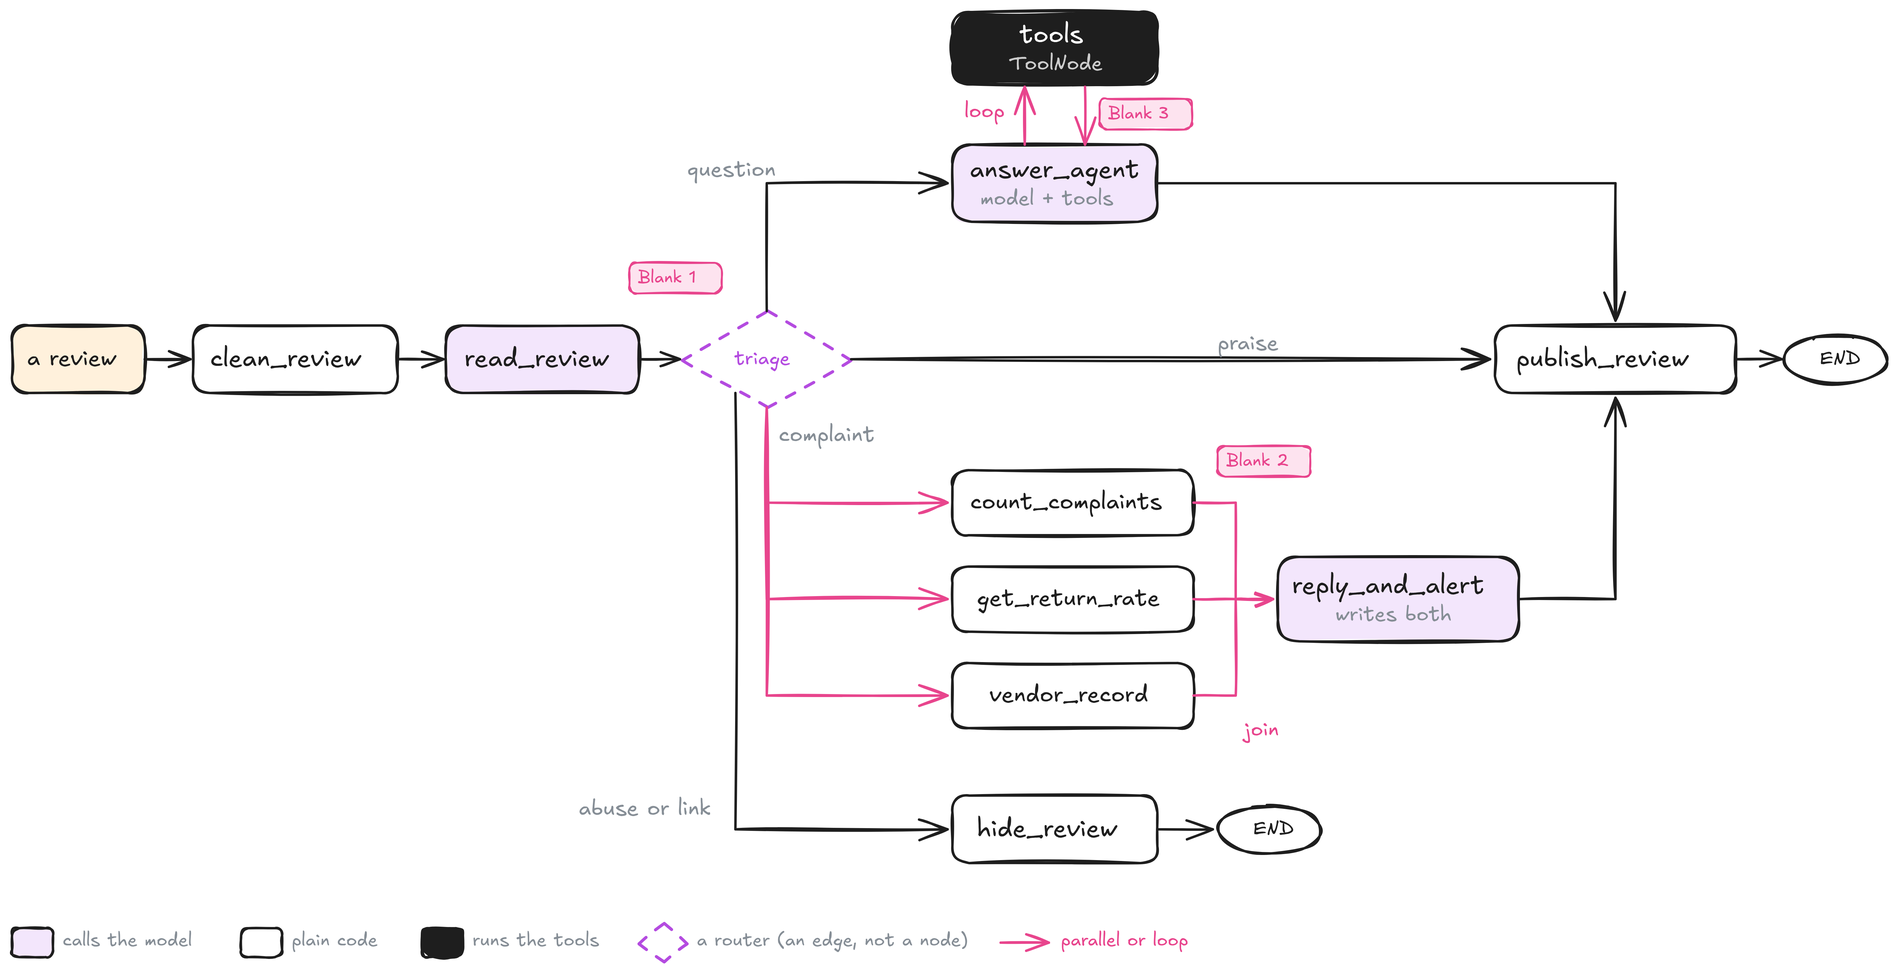

🛠️ **Your turn:** fill the 3 blanks in the next cell.

<table style="border-collapse:collapse;"><tr><td style="text-align:left;vertical-align:top;padding:4px 12px;white-space:nowrap;"><b>Blank 1</b></td><td style="text-align:left;vertical-align:top;padding:4px 12px;">after <code>"read_review"</code>, the router <code>triage</code>.</td></tr><tr><td style="text-align:left;vertical-align:top;padding:4px 12px;white-space:nowrap;"><b>Blank 2</b></td><td style="text-align:left;vertical-align:top;padding:4px 12px;">the join: from all of <code>LOOKUPS</code> to <code>"reply_and_alert"</code>.</td></tr><tr><td style="text-align:left;vertical-align:top;padding:4px 12px;white-space:nowrap;"><b>Blank 3</b></td><td style="text-align:left;vertical-align:top;padding:4px 12px;">the edge that closes the tool loop.</td></tr></table>

<details><summary><b>Hint</b></summary>

- You wrote each of these once before: Blank 1 in Part 2c, Blank 2 in Part 4c, Blank 3 in Part 6c.
- Only the graph's name is different here: `full`.

</details>

In [255]:
from langgraph.graph import StateGraph, START, END
from langgraph.prebuilt import ToolNode

full = StateGraph(ReviewState)

# 1. Register the main nodes
full.add_node("clean_review", clean_review)
full.add_node("read_review", read_review)
full.add_node("hide_review", hide_review)
full.add_node("publish_review", publish_review)
full.add_node("reply_and_alert", reply_and_alert)
full.add_node("answer_agent", answer_agent)
full.add_node("tools", ToolNode(TOOLS))

# 2. Register the three complaint lookup nodes
for name, fn in LOOKUP_NODES.items():
    full.add_node(name, fn)

# 3. Start and read the review
full.add_edge(START, "clean_review")
full.add_edge("clean_review", "read_review")

# 4. Triage chooses one destination—or all three lookups
full.add_conditional_edges(
    "read_review",
    triage,
    [
        "answer_agent",
        "publish_review",
        "hide_review",
        "count_complaints",
        "get_return_rate",
        "vendor_record",
    ],
)

# 5. Complaint lane: wait for all three lookups
full.add_edge(LOOKUPS, "reply_and_alert")
full.add_edge("reply_and_alert", "publish_review")

# 6. Question lane: agent ↔ tools
full.add_conditional_edges(
    "answer_agent",
    after_agent,
    ["tools", "publish_review"],
)
full.add_edge("tools", "answer_agent")

# 7. Finish
full.add_edge("hide_review", END)
full.add_edge("publish_review", END)

# 8. Compile once, after all nodes and edges are added
review_system = full.compile()

In [256]:
# # Part 7a: the nodes
# from langgraph.graph import StateGraph, START, END
# from langgraph.prebuilt import ToolNode
# full = StateGraph(ReviewState)
# full.add_node("clean_review", clean_review)
# full.add_node("read_review", read_review)
# full.add_node("hide_review", hide_review)
# full.add_node("publish_review", publish_review)
# for name, fn in LOOKUP_NODES.items():
#     full.add_node(name, fn)
# full.add_node("reply_and_alert", reply_and_alert)
# full.add_node("answer_agent", answer_agent)
# full.add_node("tools", ToolNode(TOOLS))
# LANES = ["hide_review", "publish_review", "answer_agent"] + LOOKUPS

In [257]:
# # Part 7a: the edges
# full.add_edge(START, "clean_review")
# full.add_edge("clean_review", "read_review")                                                   # 🛠️ Blank 1
# full.add_conditional_edges(
#     "read_review",
#     triage,
#     {
#         "answer_agent": "answer_agent",
#         "publish_review": "publish_review",
#         "look_up_facts": "look_up_facts",
#         "hide_review": "hide_review",
#     },
# )
# for lane in LANES:
#     graph.add_edge(lane, END)
#     app = graph.compile()                                 # 🛠️ Blank 2
# full.add_edge("hide_review", END)
# full.add_edge("publish_review", END)

# for name, fn in LOOKUP_NODES.items():
#     at_once.add_node(name, fn)
# at_once.add_edge(START, "count_complaints")
# at_once.add_edge(START, "get_return_rate")
# at_once.add_edge(START, "vendor_record")                                                   # 🛠️ Blank 1
# def join(state: ReviewState):
#     return {}

# at_once.add_node("join", join)

# # Wait for all three nodes before running join.
# at_once.add_edge(
#     ["count_complaints", "get_return_rate", "vendor_record"],
#     "join"
# )
# at_once.add_edge("join", END) 
# full.add_conditional_edges("answer_agent", after_agent, ["tools", "publish_review"])
# for name, fn in LOOKUP_NODES.items():
#     lane.add_node(name, fn)
#     lane.add_edge(START, name)
# lane.add_node("reply_and_alert", reply_and_alert)
# lane.add_node("publish_review", publish_review)

# # Wait for ALL three lookups
# lane.add_edge(LOOKUPS, "reply_and_alert")
# # lane.add_edge(START, reply_and_alert)                                                   # 🛠️ Blank 1
# lane.add_edge("reply_and_alert", "publish_review")                                                   # 🛠️ Blank 2
# lane.add_edge("publish_review", END)
# complaint_lane = lane.compile()                                                   # 🛠️ Blank 3

# review_system = full.compile()

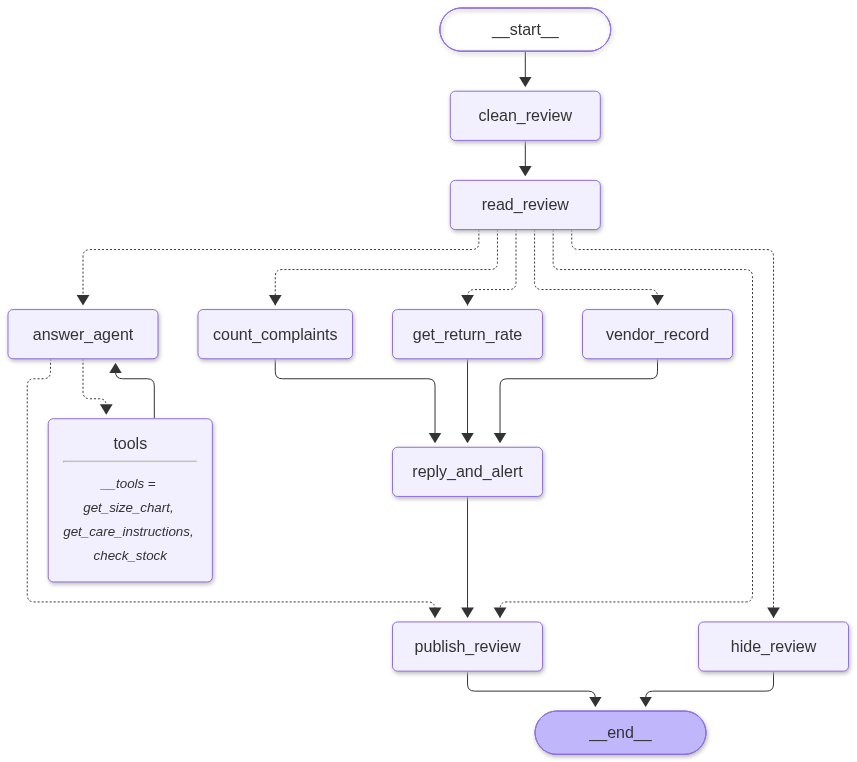

In [258]:
# Draw the graph you just built
show(review_system)

In [259]:
# ✅ Checks your work. Just run it.

edges = {(e.source, e.target) for e in review_system.get_graph().edges}
expected = {("__start__", "clean_review"), ("clean_review", "read_review"),
            ("read_review", "hide_review"), ("read_review", "publish_review"),
            ("read_review", "answer_agent"), ("answer_agent", "tools"), ("tools", "answer_agent"),
            ("answer_agent", "publish_review"), ("reply_and_alert", "publish_review"),
            ("hide_review", "__end__"), ("publish_review", "__end__")}
expected |= {("read_review", n) for n in LOOKUPS} | {(n, "reply_and_alert") for n in LOOKUPS}
check("Every edge is there", expected <= edges, f"Missing: {expected - edges}")
check("No extra edges", edges <= expected, f"Extra: {edges - expected}")

✅ Every edge is there
✅ No extra edges


**Predict first:** for each review, which lane, and how does it end? Then run 7b. `stream` hands you each step as it runs, so you can print the path.

In [260]:
# Part 7b (given): run every review and print its path
def run_all(graph, reviews=REVIEWS):
    MODERATION_QUEUE.clear(); PUBLISHED.clear(); QUALITY_ALERTS.clear()
    finals = {}
    for r in reviews:
        path = []
        for mode, chunk in graph.stream({"review": r}, stream_mode=["updates", "values"]):
            if mode == "updates":
                path += list(chunk)                # the node(s) that just ran
            else:
                finals[r["review_id"]] = chunk     # the state so far
        print(r["review_id"], "->", " -> ".join(path))
    return finals

finals = run_all(review_system)

R-1 -> clean_review -> read_review -> publish_review
R-2 -> clean_review -> read_review -> answer_agent -> tools -> answer_agent -> publish_review

Customer reply: We're sorry to hear about the issue with the colors bleeding. Thank you for bringing this to our attention; we’ve passed your feedback on to our quality team for review.

Quality alert: **Alert for Quality Team:**  
Spike detected for product HS-201:  
- 6 complaints regarding color bleeding.  
- 16% return rate exceeds threshold.  
- 2 vendor quality alerts in the last 90 days.  
Immediate investigation required.
R-3 -> clean_review -> read_review -> count_complaints -> get_return_rate -> vendor_record -> reply_and_alert -> publish_review

Customer reply: We're sorry to hear about the strap button issue and appreciate your feedback. We've passed your comments on to our quality team for review. Thank you for bringing this to our attention!

Quality alert: **Alert for Quality Team:**  
Spike detected for product HS-305:  
1. 

In [266]:
r3 = {
    "review": REVIEWS[2],
    "text": REVIEWS[2]["text"],
    "kind": "complaint",
}

print("Triage returns:", triage(r3))
print("LOOKUPS:", LOOKUPS)

Triage returns: ['count_complaints', 'get_return_rate', 'vendor_record']
LOOKUPS: ['count_complaints', 'get_return_rate', 'vendor_record']


In [267]:
# ✅ Checks your work. Just run it.

f = finals
check("R-5 and R-6 are hidden", MODERATION_QUEUE == ["R-5", "R-6"], MODERATION_QUEUE)
check("R-5's phone number never reached the model", "98200" not in f["R-5"]["text"])
check("R-2 and R-7 have an answer", f["R-2"].get("answer") and f["R-7"].get("answer"))
check("R-3 and R-4 have a reply", f["R-3"].get("reply") and f["R-4"].get("reply"))
check("R-1 is published as it is", f["R-1"]["status"] == "published")
ids = [p["review_id"] for p in PUBLISHED]
check("5 reviews published, each once", sorted(ids) == ["R-1", "R-2", "R-3", "R-4", "R-7"], ids)

❌ R-5 and R-6 are hidden  []
✅ R-5's phone number never reached the model
✅ R-2 and R-7 have an answer
✅ R-3 and R-4 have a reply
✅ R-1 is published as it is
❌ 5 reviews published, each once  ['N-1', 'N-2', 'N-3', 'N-4']


### 7c. Try reviews it has never seen

Four new reviews. Predict each path first, then run. Add your own at the end of the list.

In [269]:
# Part 7c: new reviews (given): add your own and run again
NEW_REVIEWS = [
    review("N-1", "HS-305", 5, "Great fit, my daughter loves the dungaree."),
    review("N-2", "HS-201", 3, "Does it fit a 95 cm toddler, and is it in stock?"),
    review("N-3", "HS-118", 2, "The print started peeling after two washes."),
    review("N-4", "HS-412", 1, "You idiots sent the wrong pair. Email me at riya.k@gmail.com"),
]
new = run_all(review_system, NEW_REVIEWS)
for rid, f in new.items():
    print(rid, "|", f["status"], "|", f.get("answer") or f.get("reply") or f["text"])

N-1 -> clean_review -> read_review -> publish_review
N-2 -> clean_review -> read_review -> answer_agent -> tools -> answer_agent -> publish_review

Customer reply: We're sorry to hear about the issue with your print. Thank you for bringing this to our attention; we’ve passed your feedback on to our quality team for review.

Quality alert: **Alert for Quality Team:**  
Spike detected for product HS-118:  
1. 5+ complaints received in the last 14 days.  
2. Batch return rate at 5.0%.  
3. 1 vendor quality alert in the last 90 days.  

Immediate investigation required.
N-3 -> clean_review -> read_review -> count_complaints -> get_return_rate -> vendor_record -> reply_and_alert -> publish_review

Customer reply: We're sorry to hear about the mix-up and appreciate your feedback. Your concern has been passed on to our quality team for review. For returns, please visit the Orders page. Thank you!

Quality alert: **Alert for Quality Team:**  
Spike detected for product HS-412.  
1. 5+ complain

**Now think about**
- Every review took a different path through the same graph. Which part of the graph made that happen? <details><summary>Sample answer</summary>The routers: `triage` picks the lane, and `after_agent` decides when the loop ends.</details>

**To further explore:** Docs: [Streaming](https://docs.langchain.com/oss/python/langgraph/streaming) · Guide: [freeCodeCamp: Learn LangGraph](https://www.freecodecamp.org/news/learn-langgraph-and-build-conversational-ai-with-python/) · Video: [LangChain Academy: Introduction to LangGraph (free)](https://academy.langchain.com/courses/intro-to-langgraph)

## You built it

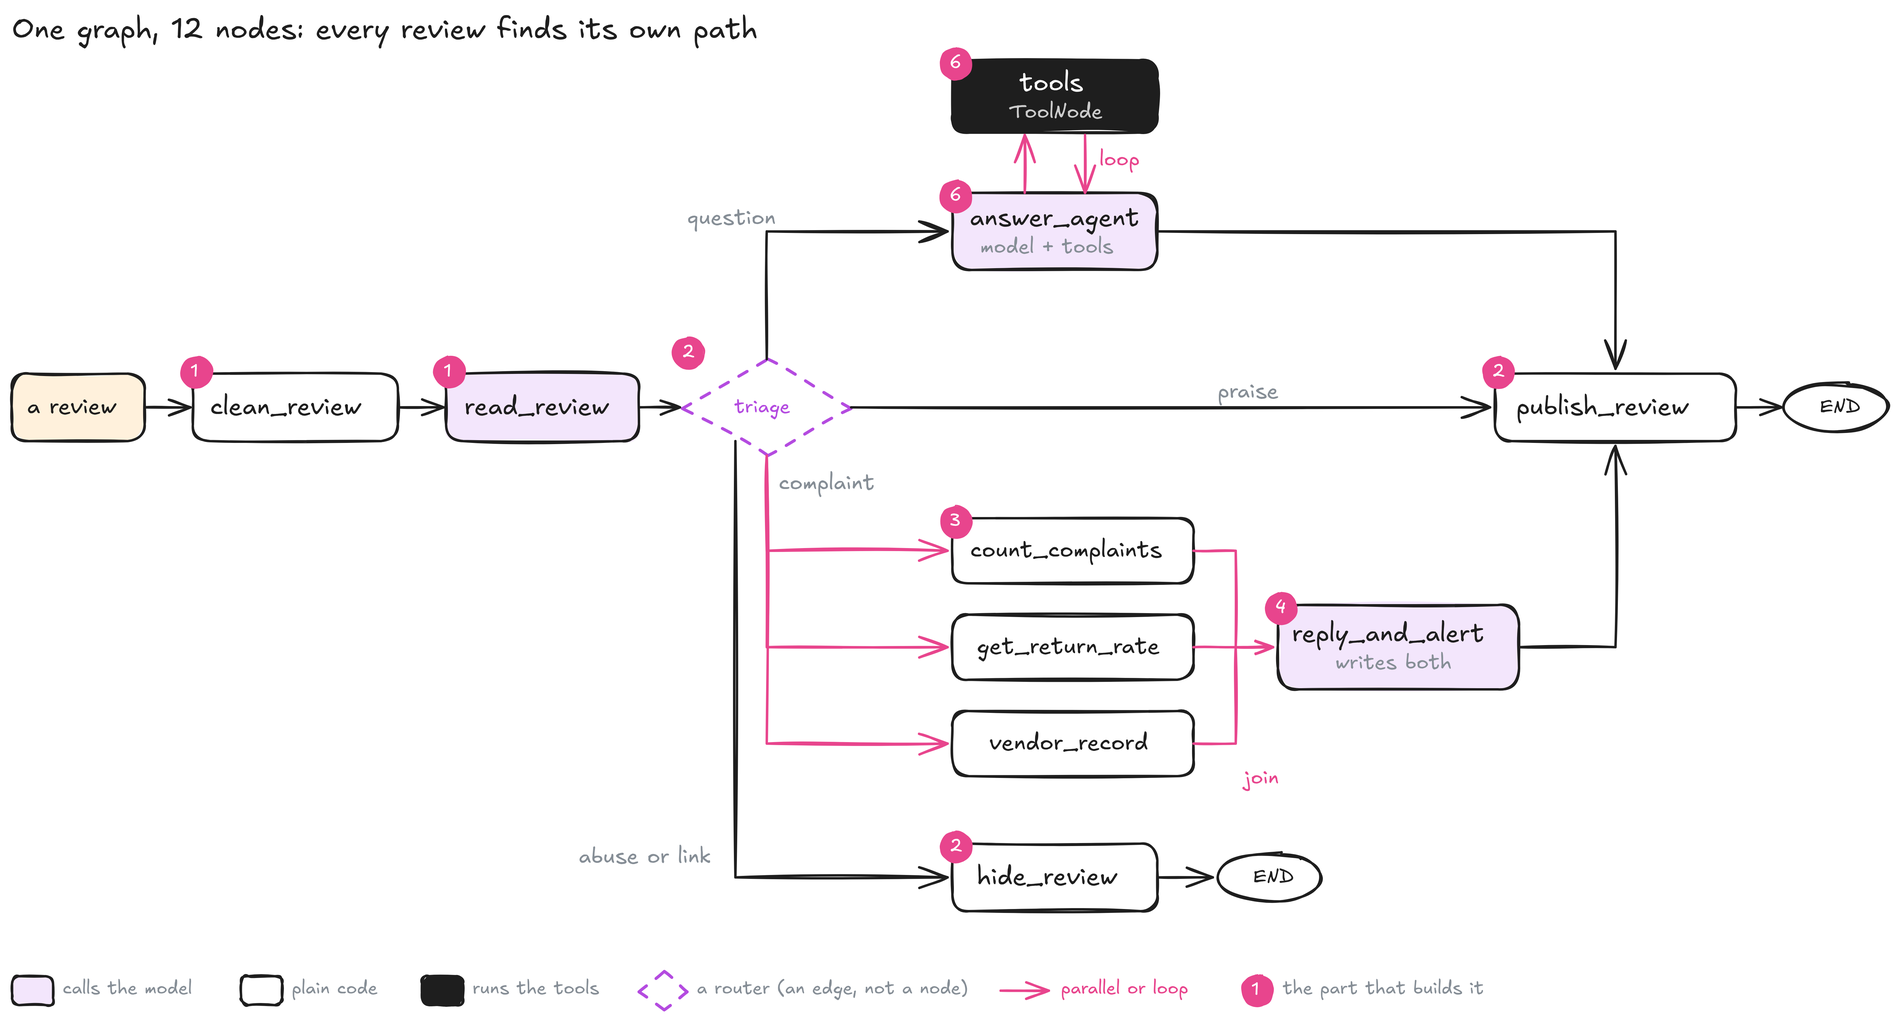

## Wrap up (part of your submission)

Answer each in one or two sentences.

1. Which nodes call the model, and which are plain code? Why is `triage` plain code?
2. Why do complaints use plain-code lookups, but questions use tools?
3. What does `Annotated[list, operator.add]` do, and what would break in the tool loop without it?
4. Why does `reply_and_alert` wait for all 3 lookups?

*Your answers:*

1. ...
2. ...
3. ...
4. ...

**Submit:** run all cells, check every ✅, and submit the `.ipynb`.

<div style="background:#020B21;color:#FFFFFF;padding:12px 16px;border-left:6px solid #FFCA8B;border-radius:6px;">
<span style="color:#FFCA8B;font-size:12px;letter-spacing:1px;">EXTEND IT YOURSELF · OPTIONAL · NO CELLS GIVEN</span><br>
<span style="font-size:20px;font-weight:700;">Two improvements to build on your own</span></div>

Add your own cells below. The Part 7 graph runs before you start; your new graph should run all 7 reviews after.

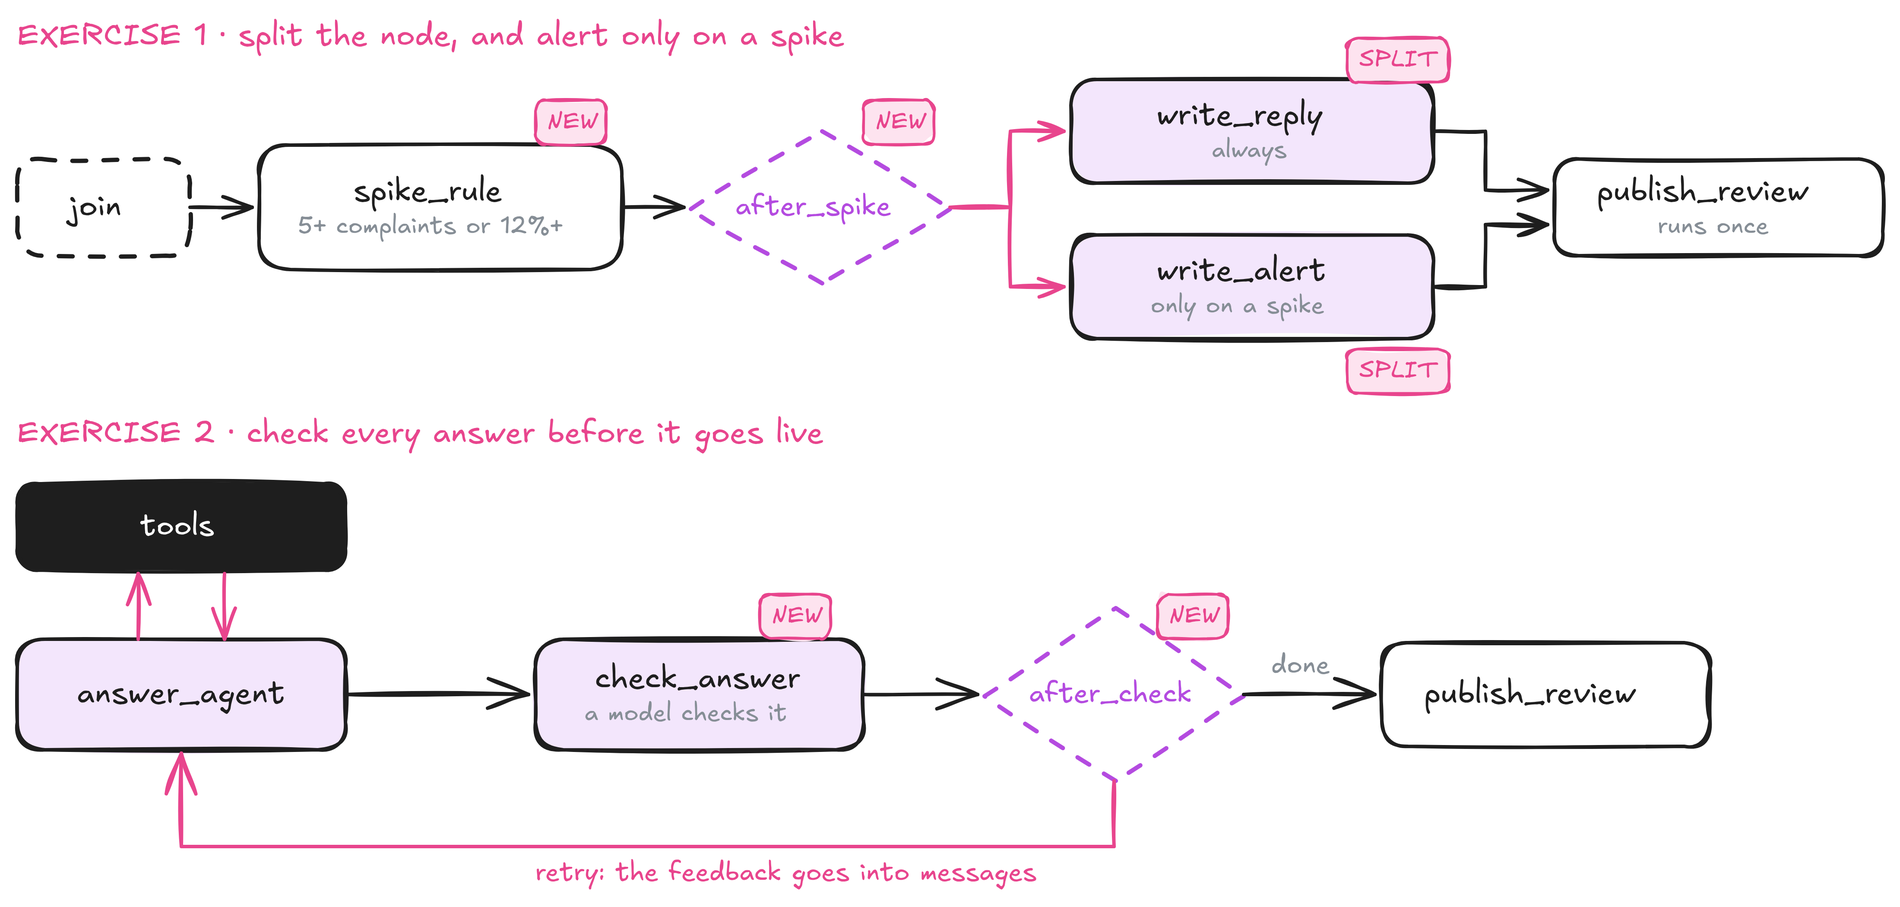

**Exercise 1 · Split the node, and alert only on a spike**

1. Split `reply_and_alert` into `write_reply` and `write_alert`.
2. Add `alert: bool` and `priority: str` to the state.
3. Add a plain-code `spike_rule`: a spike if 5+ complaints **or** a 12%+ return rate; `"high"` priority if the vendor has 2+ alerts.
4. Add a router `after_spike`: on a spike, return both writers (they run in parallel); otherwise only `"write_reply"`.
5. Rewire: join → `spike_rule` → `after_spike` → writers → `publish_review`.

*Done when:* only R-3 raises an alert, high priority, and every review is published once.

**Exercise 2 · Check every answer before it goes live**

1. Add a model node `check_answer` (structured output: `ok`, `problem`) with 3 rules: answer every question; no discounts, refunds or dates; under 50 words.
2. On a fail: clear `answer`, and add the feedback to `messages` as a `HumanMessage`, so the agent can retry, or call a tool again.
3. Add a router `after_check` returning `"done"` or `"retry"`, with a path map: `{"done": "publish_review", "retry": "answer_agent"}`. Cap it with `MAX_ROUNDS = 2`.
4. Send a finished answer from `after_agent` to `check_answer`, not `publish_review`.

*Done when:* every answer is checked at most twice, and a bad one is rewritten.

**More ideas**

- **A judge model:** after the run, score every reply and answer from 1 to 5 with a second model. A decision model like **Jev** (TypeSafe AI) returns a score with a confidence, cheaply.
- **A small model for hiding:** a `check_safety` node after `clean_review` that uses a small model to send abuse and spam straight to `hide_review`. Compare accuracy, speed and cost.

**To further explore:** Docs: [Create and control loops](https://docs.langchain.com/oss/python/langgraph/use-graph-api#create-and-control-loops) · Guide: [Evaluator-optimizer](https://docs.langchain.com/oss/python/langgraph/workflows-agents#evaluator-optimizer) · Guide: [Jev with LangChain](https://www.langchain.com/blog/building-a-harness-with-jev) · Video: [DeepLearning.AI: AI Agents in LangGraph](https://www.deeplearning.ai/short-courses/ai-agents-in-langgraph)